# TUH meta features — what do we know about the patients and recordings?

📄 **[PDF version](tuab_meta_features.pdf)**

**Part I** (Sections 1–7) covers TUAB. **Part II** (Sections 8–15) repeats the analysis on the TUEG
brain-age cohort `all_both_v3` (29k recordings), where NEDC's clinical sheet adds diagnoses,
medications and the report's reason for an abnormal read.

The fine-tuning task only ever sees **EEG windows + a binary normal/abnormal label**.
This notebook takes stock of everything *else* we know about each recording, and asks
whether any of it is useful for training or prediction.

**Sources of meta information (all read-only):**

| Source | What it gives | How |
|---|---|---|
| Directory layout | normal/abnormal label, official train/eval split | path |
| EDF patient field | **age**, **sex**, subject id | `labram/data/tuh_metadata.py` |
| EDF recording field | **session number** (patient's n-th TUH EEG), **year**, equipment tag | same |
| EDF signal headers | sampling rate, amplifier range, channel inventory (EKG, EMG, EOG, photic, **sphenoidal electrodes**) | `labram/data/tuh_meta_features.py` |
| Auxiliary channels | **heart rate / HRV** from the EKG lead, **photic stimulation** performed, device-computed **burst-suppression trends** | same |
| The EEG itself | **signal quality** (clipping, flat/noisy electrodes, artifacts, mains noise) and **qEEG** summaries (slowing, posterior dominant rhythm, asymmetry, sharp transients) | same |
| Processed windows | which recordings made it into `processed/` and which split | `processed_npy/manifest.json` |

The per-recording table is built once by
`python dataset_maker/make_TUAB_meta.py --root <edf dir>` (≈25 min, 8 cores) and cached as
`processed/meta_features.csv`; this notebook only loads and analyses it.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from labram.eval.meta_analysis import (
    FEATURE_GROUPS, SIGNATURES, add_derived_columns, available_features, feature_group_of,
    feature_inventory,
    metadata_baseline, signature_flags, univariate_auc,
)

# TUAB v3.0.1 (EDFs byte-identical to v3.0.0). The v3.0.0 sweep's table was kept
# beside the retired window pickles.
EDF_ROOT = Path("/data/datasets/EEG-public/TUH_EEG/tuab/v3.0.1/edf")
META_CSV = EDF_ROOT / "legacy_v3.0.0_processed" / "meta_features.csv"
MANIFEST = EDF_ROOT / "processed_npy" / "manifest.json"
NPY_DIR = EDF_ROOT / "processed_npy" / "recordings"

# Plot conventions: one fixed colour per class, recessive grid, no top/right spines.
C_NORMAL, C_ABNORMAL, C_NEUTRAL = "#2a78d6", "#eb6834", "#8a8984"
CLASS_COLORS = {"normal": C_NORMAL, "abnormal": C_ABNORMAL}
GROUP_COLORS = dict(zip(FEATURE_GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]))
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False,
})
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)

In [2]:
df = pd.read_csv(META_CSV)
df["error"] = df["error"].fillna("")
df = add_derived_columns(df)

manifest = json.loads(MANIFEST.read_text())
proc = pd.DataFrame(manifest["recordings"])[["stem", "source_split", "n_windows"]]
df = df.merge(proc.rename(columns={"source_split": "processed_split"}), on="stem", how="left")
df["in_processed"] = df["processed_split"].notna()

print(f"{len(df)} recordings, {df['subject'].nunique()} subjects, {df.shape[1]} columns")
print(f"extraction errors: {(df['error'] != '').sum()}")
pd.crosstab([df["tuh_split"], df["label"]], df["processed_split"].fillna("— not processed —"), margins=True)

2993 recordings, 2329 subjects, 63 columns
extraction errors: 0


processed_split     test  train  val  — not processed —   All
tuh_split label                                              
eval      abnormal   126      0    0                  0   126
          normal     150      0    0                  0   150
train     abnormal     0   1052  291                  3  1346
          normal       0   1090  281                  0  1371
All                  276   2142  572                  3  2993

## 1. Inventory — which meta features exist, and how complete are they?

Coverage = share of the 2,993 recordings where the feature has a value. A feature can
be missing because the channel was not recorded (EMG, photic), because the device did
not compute it (burst-suppression trends), or because it is a sentinel (age 999 = 90+).

Columns of the inventory table (`labram/eval/meta_analysis.py::feature_inventory`):

* **type**: *categorical* for 0/1 flags and discrete device settings (sampling rate,
  amplifier range); *quantitative* otherwise.
* **n_categories** / **categories** (categorical only): the number of distinct values, and the
  5 most frequent ones with their share of the recordings that have a value. For 0/1 flags,
  1 = yes.
* **active_range** (quantitative only): the 1st to 99th percentile of the values,
  $[Q_{0.01}(x),\ Q_{0.99}(x)]$, so a few outliers do not set the range.
* **meaning**: what a *history*, *acquisition*, *physiology* or *qEEG* feature measures, with its unit.


In [3]:
SOURCE = {
    "demographics": "EDF patient field", "history": "EDF recording field",
    "acquisition": "EDF signal headers / photic channel", "quality": "EEG signal",
    "physiology": "EKG lead / device trend channels", "qeeg": "EEG signal",
}
inventory = feature_inventory(df)
inventory.insert(2, "source", inventory["group"].map(SOURCE))
inventory.style.format({"coverage_%": "{:.1f}", "n_categories": "{:.0f}"}, na_rep="").background_gradient(
    subset=["coverage_%"], cmap="Blues", vmin=0, vmax=100).hide(axis="index")


group,feature,source,type,coverage_%,n_categories,categories,active_range,meaning
demographics,age,EDF patient field,quantitative,99.5,,,17 – 86,
demographics,sex_male,EDF patient field,categorical,100.0,2,"0 (53%), 1 (47%)",,
history,session_number,EDF recording field,quantitative,100.0,,,1 – 13,"Which EEG session of the patient this is: n-th TUH EEG session, in date order over the whole TUH archive (s003 -> 3). NOT the patient's total number of sessions"
history,year,EDF recording field,quantitative,100.0,,,2000 – 2013,Recording year (the date is anonymised to 01-JAN-YYYY); 1899 and 2000 are placeholders
acquisition,duration_min,EDF signal headers / photic channel,quantitative,100.0,,,16.8 – 51.1,Length of the recording [min]
acquisition,sfreq,EDF signal headers / photic channel,categorical,100.0,3,"250 (93%), 256 (6%), 512 (1%)",,Native sampling rate of the EEG channels [Hz]; set by the amplifier / acquisition software
acquisition,physical_max_uv,EDF signal headers / photic channel,categorical,100.0,2,"5000 (93%), 5482 (7%)",,Amplifier input range from the EDF header [±µV]; identifies the amplifier family
acquisition,n_signals,EDF signal headers / photic channel,quantitative,100.0,,,27 – 36,Channels stored in the EDF (EEG + auxiliary); a montage / amplifier fingerprint
acquisition,has_emg,EDF signal headers / photic channel,categorical,100.0,2,"1 (61%), 0 (39%)",,An EMG (muscle) channel was recorded
acquisition,has_eog,EDF signal headers / photic channel,categorical,100.0,2,"1 (93%), 0 (7%)",,"Both eye-movement channels (LOC, ROC) were recorded"


In [4]:
missing = pd.Series({
    "Age missing / sentinel (999 = 90+, 0)": df["age"].isna().sum(),
    "Sex missing": df["sex"].isna().sum(),
    "No EKG channel": (~df["has_ekg"].astype(bool)).sum(),
    "EKG present but no usable heart rate": (df["has_ekg"].astype(bool) & df["ekg_hr_bpm"].isna()).sum(),
    "No EMG channel": (df["has_emg"] == 0).sum(),
    "No photic channel": (df["has_photic_channel"] == 0).sum(),
    "Photic channel but no stimulation": ((df["has_photic_channel"] == 1) & (df["photic_performed"] == 0)).sum(),
    "Burst-suppression trend not computed": df["trend_suppr_mean"].isna().sum(),
    "EDF not in processed windows": (~df["in_processed"]).sum(),
}, name="recordings")
missing.to_frame().assign(**{"%": lambda t: 100 * t["recordings"] / len(df)})

,recordings,%
"Age missing / sentinel (999 = 90+, 0)",15,0.501
Sex missing,0,0.000
No EKG channel,0,0.000
EKG present but no usable heart rate,0,0.000
No EMG channel,1179,39.392
No photic channel,157,5.246
Photic channel but no stimulation,680,22.720
Burst-suppression trend not computed,1187,39.659
EDF not in processed windows,3,0.100


**What is *not* in the data at all** — worth stating explicitly, because it bounds every
question below:

| Wanted | Available? |
|---|---|
| **Reason the EEG is abnormal** (slowing, epileptiform discharges, seizure, …) | ❌ TUAB labels are binary. TUH stopped distributing the EEG reports, which held the findings. |
| Diagnosis, medications, indication for the EEG, ICU status | ❌ (only in the withdrawn reports) |
| Race/ethnicity, handedness, height/weight | ❌ |
| Vigilance state (awake/drowsy/asleep), eyes open/closed events | ❌ not annotated in TUAB (only indirectly: photic stimulation, PDR prominence) |
| Exact recording date / time of day | ❌ anonymised to 01-JAN-YYYY 00:00 — only the **year** survives |
| Per-recording label confidence | ⚠️ corpus-level only: the AAREADME reports 27 train files (1%) where the annotator disagreed with the report, but not *which* |

## 2. Demographics — age, sex, and patient history

**Session number** = *which* EEG session of the patient a recording belongs to: the
recording's session tag counts the patient's TUH EEG sessions in date order over the whole
TUH archive (`s001` = first EEG at Temple, `s003` = third). It is **not** the patient's total
number of sessions, and not a count within TUAB: for 23% of TUAB patients the earliest TUAB
recording is already session 2 or later. A high session number therefore means a patient who
had already been recorded many times — chronic neurological follow-up.

The **abnormal rate** of a group $G$ of recordings (an age group, a sex, a session number, ...),
with $y_i = 1$ for an abnormal and $0$ for a normal recording, is

$$ r(G) = \frac{1}{\lvert G\rvert}\sum_{i \in G} y_i . \tag{2.1} $$


age                                         
           count  mean   std  min   25%   50%   75%   max
label                                                    
abnormal  1463.0  54.4  17.2  1.0  44.0  55.0  67.0  89.0
normal    1515.0  44.0  16.1  1.0  31.0  44.0  55.0  88.0

label,abnormal,normal
share by sex,,
F,0.465,0.535
M,0.522,0.478


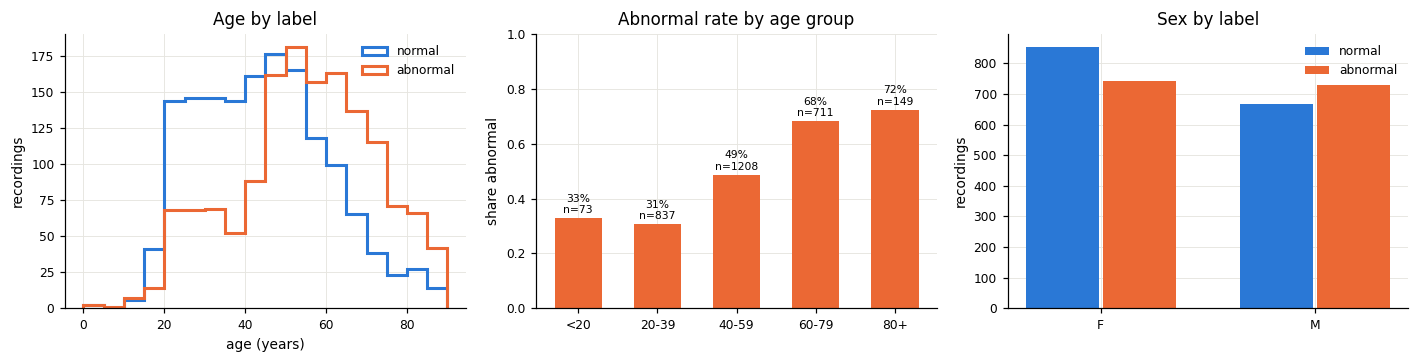

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
bins = np.arange(0, 95, 5)
for lab in ["normal", "abnormal"]:
    axes[0].hist(df.loc[df.label == lab, "age"].dropna(), bins=bins, histtype="step", lw=2,
                 color=CLASS_COLORS[lab], label=lab)
axes[0].set(title="Age by label", xlabel="age (years)", ylabel="recordings"); axes[0].legend()

rate = df.groupby("age_group", observed=True)["is_abnormal"].agg(["mean", "size"])
axes[1].bar(rate.index.astype(str), rate["mean"], color=C_ABNORMAL, width=0.6)
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    axes[1].text(i, m + 0.01, f"{m:.0%}\nn={n}", ha="center", va="bottom", fontsize=7)
axes[1].set(title="Abnormal rate by age group", ylabel="share abnormal", ylim=(0, 1))

sx = pd.crosstab(df["sex"], df["label"])
x = np.arange(len(sx))
for j, lab in enumerate(["normal", "abnormal"]):
    axes[2].bar(x + (j - 0.5) * 0.36, sx[lab], width=0.34, color=CLASS_COLORS[lab], label=lab)
axes[2].set_xticks(x, sx.index); axes[2].set(title="Sex by label", ylabel="recordings"); axes[2].legend()
plt.tight_layout()

display(df.groupby("label")[["age"]].describe().round(1))
display(pd.crosstab(df["sex"], df["label"], normalize="index").round(3).rename_axis("share by sex"))

subjects with >1 recording: 443 / 2329;  subjects with BOTH a normal and an abnormal recording: 54


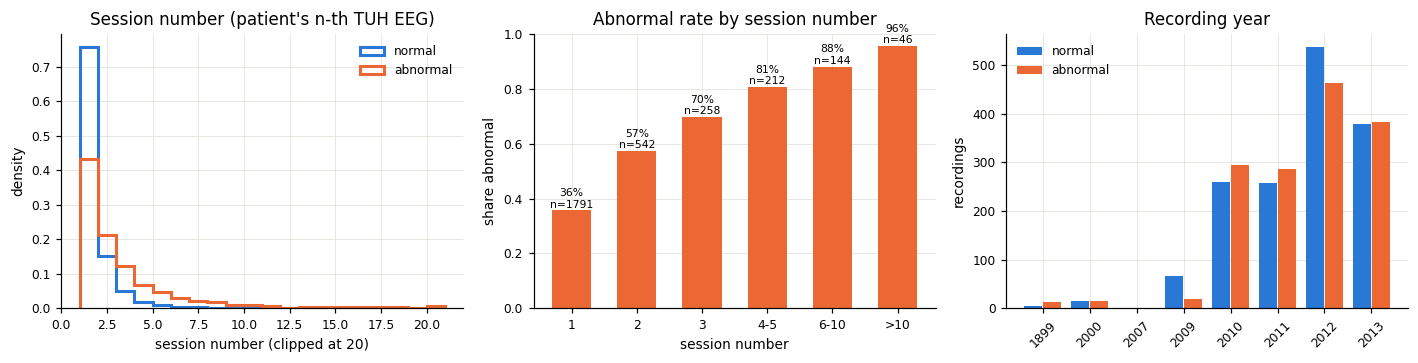

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
sn = df["session_number"].clip(upper=20)
for lab in ["normal", "abnormal"]:
    axes[0].hist(sn[df.label == lab], bins=np.arange(1, 22), histtype="step", lw=2,
                 color=CLASS_COLORS[lab], label=lab, density=True)
axes[0].set(title="Session number (patient's n-th TUH EEG)", xlabel="session number (clipped at 20)",
            ylabel="density"); axes[0].legend()

sb = df.assign(sbin=pd.cut(df["session_number"], [0, 1, 2, 3, 5, 10, 1000],
                           labels=["1", "2", "3", "4-5", "6-10", ">10"]))
r = sb.groupby("sbin", observed=True)["is_abnormal"].agg(["mean", "size"])
axes[1].bar(r.index.astype(str), r["mean"], color=C_ABNORMAL, width=0.6)
for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
    axes[1].text(i, m + 0.01, f"{m:.0%}\nn={n}", ha="center", fontsize=7)
axes[1].set(title="Abnormal rate by session number", ylabel="share abnormal", ylim=(0, 1),
            xlabel="session number")

yr = pd.crosstab(df["year"], df["label"])
x = np.arange(len(yr))
for j, lab in enumerate(["normal", "abnormal"]):
    axes[2].bar(x + (j - 0.5) * 0.4, yr[lab], width=0.38, color=CLASS_COLORS[lab], label=lab)
axes[2].set_xticks(x, yr.index, rotation=45); axes[2].set(title="Recording year", ylabel="recordings")
axes[2].legend(); plt.tight_layout()

per_subj = df.groupby("subject").agg(n=("stem", "size"), labels=("label", "nunique"))
print(f"subjects with >1 recording: {(per_subj.n > 1).sum()} / {len(per_subj)};  "
      f"subjects with BOTH a normal and an abnormal recording: {(per_subj.labels > 1).sum()}")

## 3. Acquisition setup — real information or a shortcut?

These features describe *how* the EEG was recorded, not the patient. A feature like this is
a **shortcut** when its abnormal rate differs strongly between values. A model can then learn
the hospital workflow (which room, amplifier or protocol was used for sicker patients)
instead of brain activity, and that will not transfer to another hospital. All of them are
read from the EDF file, apart from `photic_performed`, which is read from the stimulator's
signal.

| feature | what it is | values in TUAB | what it can reveal |
|---|---|---|---|
| `sfreq` | **Sampling rate**: how many samples per second the amplifier stored for each EEG channel (Hz), from the EDF signal header. | 250 Hz (93%), 256 Hz (6%), 512 Hz (1%) | Which amplifier / acquisition software was used. Preprocessing resamples everything to 200 Hz, but the original rate leaves faint traces (anti-alias filter edge, resampling artifacts). |
| `physical_max_uv` | **Amplifier input range**: the largest voltage the channel can record (± µV, EDF "physical maximum"). With 16-bit storage it also sets the resolution (range / 32,767 ≈ 0.15 µV per step). | ±4,999.8 µV (93%), ±5,482.3 µV (7%) | The amplifier model. It maps one-to-one onto the sampling rate: 4,999.8 µV ⇔ 250 Hz. |
| `equipment_tag` | **Machine name** from the EDF recording field. TUH anonymises most of it to `X`; some files keep a tag (`Compact_32ch`, `Compact_64ch`) or masked characters (`#####`). | `X` (94%), `#####` (4%), other tags (2%) | The amplifier family, wherever the tag survived. Every non-`X` tag is on the 256/512 Hz system. |
| `n_signals` | **Channels stored in the file**: EEG plus auxiliary channels (EKG, EMG, eye, photic, trend channels, spare inputs). It depends on the headbox and montage configuration of the room. | 36 (55%), 30 (34%), 27–35 (11%) | The recording room / configuration. Rare layouts (e.g. 27 channels, 81% abnormal) are almost a label on their own. |
| `has_emg` | An **EMG channel** (muscle electrode, e.g. chin or limb; used for sleep and movement work-ups). | yes 61% | Protocol. Shows no label difference (48% vs 50% abnormal). |
| `has_eog` | **Eye channels** LOC/ROC: electrodes beside the eyes that record eye movements, so eye artifacts can be told apart from frontal brain activity. | yes 93% | Missing exactly on the 256/512 Hz system, so it is the same amplifier shortcut. |
| `has_sphenoidal` | **Sphenoidal electrodes** SP1/SP2: thin wires placed near the skull base to record the deep (mesial) temporal lobe, used in epilepsy and epilepsy-surgery work-ups. | yes 3.5% | The **reason for referral** (suspected temporal-lobe epilepsy); 63% abnormal. |
| `has_numbered_extra` | **Spare amplifier inputs** stored as numbered channels (`26`…`32`) with nothing connected. | yes 59% | Headbox configuration only; no label difference (51% vs 47%). |
| `photic_performed` | **Photic stimulation**, detected from the stimulator channel. A strobe flashes at increasing rates during a routine EEG to provoke photosensitive responses; this flag says whether it was actually done. | done 72% | The **patient's state**: it is skipped in obtunded, ICU or uncooperative patients, so recordings without it are 80% abnormal vs 37% with it. The flashes also drive a visible rhythm in the occipital EEG, so the model *can* see whether it happened. |

**Four of these columns are one fact.** `sfreq` ≠ 250 Hz, `physical_max_uv` = 5,482.3,
a non-`X` `equipment_tag` and a missing EOG all mark the same second amplifier system. It
covers 207 recordings (7%), 68% of them abnormal against 48% on the main system, and only 4%
of them are in the eval split. Treat them as one shortcut, not four independent findings.
For LaBraM this matters less, because it only sees the 19–23 EEG channels after resampling;
but the **sampling rate and amplifier range survive preprocessing** as subtle
spectral/amplitude fingerprints, and photic stimulation is visible in the EEG itself.

The table below lists, per value of each feature, the number of `recordings`, the
`abnormal_rate` (share of those recordings labelled abnormal) and the `eval_share` (share of
them in the official eval split). The colour scale is centred on the overall abnormal rate,
so red = more abnormal than average and blue = less.


In [7]:
cat_cols = ["sfreq", "physical_max_uv", "equipment_tag", "n_signals", "has_emg", "has_eog",
            "has_sphenoidal", "has_numbered_extra", "photic_performed"]
rows = []
for c in cat_cols:
    for val, g in df.groupby(c, dropna=False):
        rows.append({"feature": c, "value": val, "recordings": len(g),
                     "abnormal_rate": g["is_abnormal"].mean(),
                     "eval_share": (g["tuh_split"] == "eval").mean()})
acq = pd.DataFrame(rows)
overall = df["is_abnormal"].mean()
acq.style.format({"abnormal_rate": "{:.0%}", "eval_share": "{:.0%}"}).background_gradient(
    subset=["abnormal_rate"], cmap="RdBu_r", vmin=0, vmax=2 * overall).hide(axis="index")

feature,value,recordings,abnormal_rate,eval_share
sfreq,250.000000,2786,48%,10%
sfreq,256.000000,189,71%,4%
sfreq,512.000000,18,33%,0%
physical_max_uv,4999.847000,2786,48%,10%
physical_max_uv,5482.288000,207,68%,4%
equipment_tag,#,28,82%,7%
equipment_tag,#####,116,60%,4%
equipment_tag,Compact_32ch,22,86%,0%
equipment_tag,Compact_64ch,14,64%,0%
equipment_tag,X,2813,48%,10%


## 4. Data quality — is the data good, noisy, or missing?

Computed per recording by `labram/data/tuh_meta_features.py::quality_features` over the 19
scalp electrodes $c = 1..C$. Notation: $x_c(t)$ is the raw signal (µV); $\tilde x_c(t)$ the same
signal band-passed 0.5–45 Hz (4th-order Butterworth, zero-phase); the band-passed signal is cut
into $E$ non-overlapping 10-s epochs $e$; $\sigma_{ec}$ and $\operatorname{ptp}_{ec} = \max - \min$
are the standard deviation and peak-to-peak range of $\tilde x_c$ in epoch $e$ (µV).

* **Clipping** (saturation): the share of raw samples at ≥ 99% of the amplifier range
  $V_{\max}$ (`physical_max_uv`), over all $T$ samples and channels:
$$ \mathtt{q\_clip\_frac} = \frac{1}{CT}\sum_{c,t} \mathbb{1}\big[\lvert x_c(t)\rvert \ge 0.99\,V_{\max}\big]. \tag{4.1} $$
* **Flat** and **high-amplitude** channel-epochs (a disconnected electrode; movement or an
  electrode pop):
$$ \begin{aligned} \text{flat}_{ec} &= \mathbb{1}[\sigma_{ec} < 0.5\,\mu\text{V}] \\ \text{high}_{ec} &= \mathbb{1}[\operatorname{ptp}_{ec} > 500\,\mu\text{V}]. \end{aligned} \tag{4.2} $$
* **Epoch fractions**: an epoch counts when *any* electrode is affected:
$$ \begin{aligned} \mathtt{q\_flat\_epoch\_frac} &= \frac1E\sum_e \max_c \text{flat}_{ec} \\ \mathtt{q\_high\_amp\_epoch\_frac} &= \frac1E\sum_e \max_c \text{high}_{ec} \end{aligned} \tag{4.3} $$
$$ \mathtt{q\_bad\_epoch\_frac} = \frac1E\sum_e \max_c \big(\text{flat}_{ec} \vee \text{high}_{ec}\big). \tag{4.4} $$
* **Flat electrodes**: flat in more than half of the epochs,
  $\mathtt{q\_n\_flat\_channels} = \sum_c \mathbb{1}\big[\tfrac1E\sum_e \text{flat}_{ec} > 0.5\big]$.
  **Noisy electrodes**: not flat, but with a whole-recording amplitude that is a robust
  outlier among the recording's electrodes. With $s_c = \ln(\operatorname{std}_t \tilde x_c + 10^{-6})$:
$$ \mathtt{q\_n\_noisy\_channels} = \sum_c \mathbb{1}\left[\frac{\lvert s_c - \operatorname{med}_{c'} s_{c'}\rvert}{1.4826\,\big(\operatorname{MAD}_{c'} s_{c'} + 10^{-6}\big)} > 5\right]\big(1 - \text{flatch}_c\big), \tag{4.5} $$
  where $\operatorname{MAD}$ is the median absolute deviation from the median, $1.4826$ makes it
  a standard-deviation estimate for Gaussian data, and $\text{flatch}_c$ marks a flat electrode.
* **Median amplitude**: $\mathtt{q\_median\_amp\_uv} = \operatorname{med}_{e,c}\ \sigma_{ec}$ (µV).
* **Mains noise**: with $\bar P(f)$ the Welch power spectrum of the *raw* signal (2-s Hann
  windows, 50% overlap) averaged over electrodes, the log-share of power within ±1 Hz of the
  mains frequency $f_0 \in \{50, 60\}$ Hz:
$$ \mathtt{q\_line}f_0\mathtt{\_log\_ratio} = \log_{10}\left(\frac{\sum_{\lvert f - f_0\rvert \le 1} \bar P(f)}{\sum_{1 \le f \le 45} \bar P(f)} + 10^{-12}\right). \tag{4.6} $$

The **quality tier** used below (code cell after Figure "share of artifact epochs"), with
$b$ = `q_bad_epoch_frac`, $n_{\text{flat}}$, $n_{\text{noisy}}$ the electrode counts and
$k$ = `q_clip_frac`:
$$ \text{tier} = \begin{cases} \text{poor} & n_{\text{flat}} \ge 2 \ \vee\ b > 0.3 \ \vee\ k > 0.01 \\ \text{fair} & \text{else if } n_{\text{flat}} + n_{\text{noisy}} \ge 1 \ \vee\ b > 0.1 \\ \text{good} & \text{otherwise.} \end{cases} \tag{4.7} $$


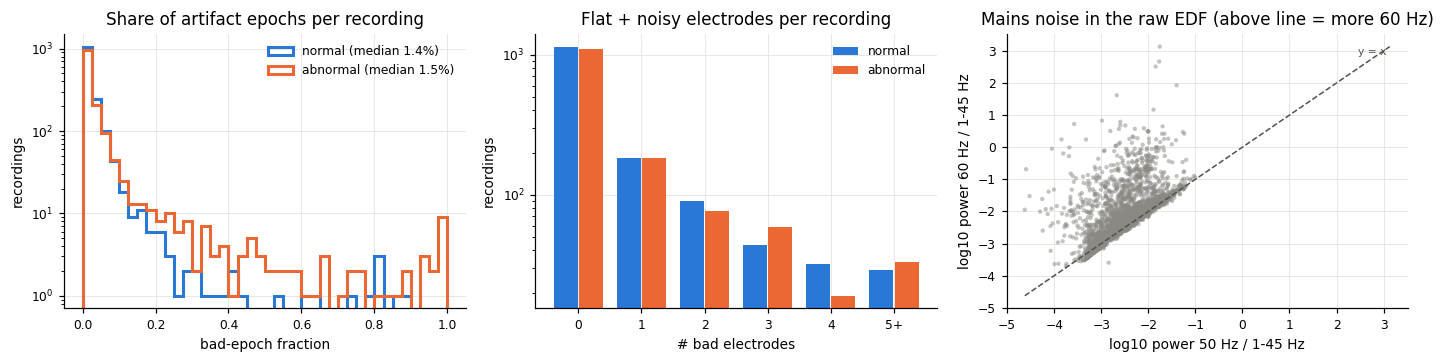

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for lab in ["normal", "abnormal"]:
    s = df.loc[df.label == lab, "q_bad_epoch_frac"]
    axes[0].hist(s, bins=np.linspace(0, 1, 41), histtype="step", lw=2, color=CLASS_COLORS[lab],
                 label=f"{lab} (median {s.median():.1%})")
axes[0].set(title="Share of artifact epochs per recording", xlabel="bad-epoch fraction",
            ylabel="recordings", yscale="log"); axes[0].legend()

ch = df.assign(bad_ch=(df["q_n_flat_channels"] + df["q_n_noisy_channels"]).clip(upper=5))
t = pd.crosstab(ch["bad_ch"], ch["label"])
x = np.arange(len(t))
for j, lab in enumerate(["normal", "abnormal"]):
    axes[1].bar(x + (j - 0.5) * 0.4, t[lab], width=0.38, color=CLASS_COLORS[lab], label=lab)
axes[1].set_xticks(x, [str(i) if i < 5 else "5+" for i in t.index])
axes[1].set(title="Flat + noisy electrodes per recording", xlabel="# bad electrodes", ylabel="recordings",
            yscale="log"); axes[1].legend()

axes[2].scatter(df["q_line50_log_ratio"], df["q_line60_log_ratio"], s=8, alpha=0.5, color=C_NEUTRAL,
                edgecolor="none")
lim = [min(df["q_line50_log_ratio"].min(), df["q_line60_log_ratio"].min()),
       max(df["q_line50_log_ratio"].max(), df["q_line60_log_ratio"].max())]
axes[2].plot(lim, lim, color="#52514e", lw=1, ls="--")
axes[2].text(lim[1], lim[1], "y = x ", fontsize=7, color="#52514e", va="top", ha="right")
axes[2].set(title="Mains noise in the raw EDF (above line = more 60 Hz)", xlabel="log10 power 50 Hz / 1-45 Hz",
            ylabel="log10 power 60 Hz / 1-45 Hz")
plt.tight_layout()

In [9]:
def tier(r):
    if r.q_n_flat_channels >= 2 or r.q_bad_epoch_frac > 0.3 or r.q_clip_frac > 0.01:
        return "poor"
    if r.q_n_flat_channels + r.q_n_noisy_channels >= 1 or r.q_bad_epoch_frac > 0.1:
        return "fair"
    return "good"

df["quality_tier"] = df.apply(tier, axis=1)
display(pd.crosstab([df["tuh_split"], df["label"]], df["quality_tier"], margins=True)[["good", "fair", "poor", "All"]])
# Recording ids are left out on purpose: they stay out of git (DUA); look them up locally.
print("Worst recordings by artifact share:")
df.sort_values("q_bad_epoch_frac", ascending=False)[
    ["label", "tuh_split", "age", "q_bad_epoch_frac", "q_clip_frac", "q_n_flat_channels",
     "q_n_noisy_channels", "q_median_amp_uv", "duration_min"]].head(10)

quality_tier        good  fair  poor   All
tuh_split label                           
eval      abnormal    92    30     4   126
          normal     106    41     3   150
train     abnormal   921   361    64  1346
          normal     997   359    15  1371
All                 2116   791    86  2993

Worst recordings by artifact share:


,label,tuh_split,age,q_bad_epoch_frac,q_clip_frac,q_n_flat_channels,q_n_noisy_channels,q_median_amp_uv,duration_min
1392,abnormal,train,20.0,1.000,4.644e-03,0,3,36.371,29.400
1202,abnormal,train,34.0,1.000,0.000e+00,0,0,114.400,16.400
1186,abnormal,train,49.0,1.000,0.000e+00,0,0,68.063,23.917
1507,abnormal,train,29.0,1.000,1.925e-01,0,0,1731.404,18.083
65,abnormal,eval,43.0,0.996,0.000e+00,3,0,0.719,45.433
1231,abnormal,train,20.0,0.993,1.637e-04,0,0,38.081,24.750
1590,abnormal,train,42.0,0.990,0.000e+00,8,0,0.598,34.050
1222,abnormal,train,49.0,0.990,0.000e+00,6,0,0.635,50.500
1349,abnormal,train,51.0,0.977,2.865e-05,0,0,34.768,21.800
352,abnormal,train,71.0,0.975,7.012e-07,2,0,1.146,40.033


### Does the preprocessing remove the mains noise?

`dataset_maker/make_TUAB.py` band-passes 0.1–75 Hz and applies a **50 Hz** notch. TUH was
recorded in Philadelphia, where the mains frequency is **60 Hz** — so the notch misses it
and the 75 Hz low-pass keeps it. Checked directly on a sample of the processed windows
the model trains on:

60 Hz peak vs 55-58 Hz floor: median x2.2, >10x in 17% of sampled recordings


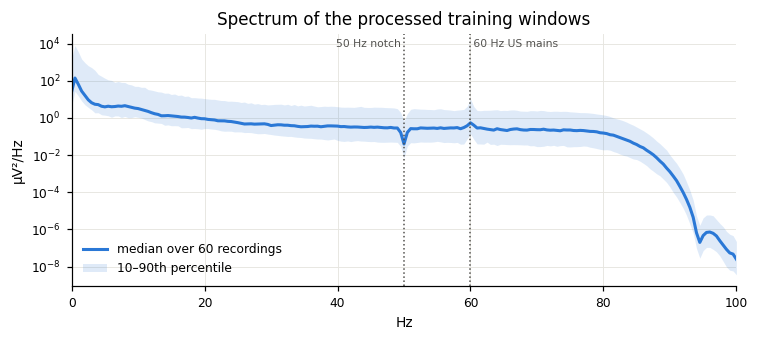

In [10]:
from scipy.signal import welch
rng = np.random.default_rng(0)
sample = rng.choice(df.loc[df.in_processed, "stem"].to_numpy(), size=60, replace=False)
psds = []
for stem in sample:
    x = np.load(NPY_DIR / f"{stem}.npy", mmap_mode="r")[: 200 * 300]      # first 5 min
    f, p = welch(np.asarray(x, dtype=np.float64), fs=200, nperseg=400, axis=0)
    psds.append(p.mean(axis=1))
psds = np.array(psds)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.semilogy(f, np.median(psds, axis=0), color=C_NORMAL, lw=2, label="median over 60 recordings")
ax.fill_between(f, np.percentile(psds, 10, axis=0), np.percentile(psds, 90, axis=0), color=C_NORMAL,
                alpha=0.15, lw=0, label="10–90th percentile")
for f0, txt, ha in [(50, "50 Hz notch ", "right"), (60, " 60 Hz US mains", "left")]:
    ax.axvline(f0, color="#52514e", lw=1, ls=":")
    ax.text(f0, ax.get_ylim()[1] * 0.2, txt, fontsize=7, ha=ha, color="#52514e")
ax.set(title="Spectrum of the processed training windows", xlabel="Hz", ylabel="µV²/Hz", xlim=(0, 100))
ax.legend(); plt.tight_layout()
i60, ibase = np.argmin(abs(f - 60)), (f > 55) & (f < 58)
ratio = psds[:, i60] / psds[:, ibase].mean(axis=1)
print(f"60 Hz peak vs 55-58 Hz floor: median x{np.median(ratio):.1f}, "
      f">10x in {(ratio > 10).mean():.0%} of sampled recordings")

## 5. Why is a case abnormal?

TUAB does not say. The clinical reasons for an "abnormal" EEG read are, in rough order of
frequency: **background slowing** (diffuse or focal), a **slow or absent posterior dominant
rhythm**, **asymmetry**, **epileptiform discharges** (spikes/sharp waves), and rarer patterns
(burst-suppression, low voltage). Most of these have a quantitative EEG proxy, so we can
recover a *putative* reason per recording:

* each signature is a qEEG feature + the direction in which it becomes abnormal;
* the threshold is the 95th (or 5th) percentile of **normal training recordings in the same
  age group** — so ~5% of normals are flagged by construction, and age effects (the PDR slows
  with age) don't masquerade as abnormality.

These are *screening phenotypes*, not diagnoses — epileptiform discharges in particular are
brief and rarely move a whole-recording statistic.

### Are the signatures taken from medical records?

**No.** Every signature is **calculated**; none comes from a medical record:

| | where it comes from |
|---|---|
| **The signature names** (diffuse slowing, focal slowing, slow / absent PDR, asymmetry, sharp transients, low voltage) | **Clinical EEG knowledge**: the usual reasons an EEG reader calls a recording abnormal. The categories, and the one qEEG feature chosen for each with the direction in which it becomes abnormal (`SIGNATURES` in `labram/eval/meta_analysis.py`, e.g. "diffuse slowing ↔ high slowing ratio"), are a rule written down for this analysis, not data. |
| **Whether a recording has a signature** | **Computed from its EEG signal.** The qEEG features of Eqs. (5.1)–(5.9) are computed by `labram/data/tuh_meta_features.py::qeeg_features` from each EDF. A recording is flagged when its feature lies beyond the 95th (or 5th) percentile of age-matched *normal training* recordings, Eqs. (5.13)–(5.14). The 95% level is a convention, so ≈5% of normals are flagged by design. |
| **Medical records of TUAB** | **None exist.** TUAB ships only the normal/abnormal folder label. TUH stopped distributing the EEG reports, which held the findings, diagnosis and medication. |

So for TUAB a signature is a **hypothesis** about *why* a recording is abnormal, generated
from the signal.

Medical-record information exists only for the **TUEG cohort** in Part II, through NEDC's
clinical metadata sheet:
* the report's free-text **"abnormal due to"** reason (e.g. "generalized background
  slowing", "left temporal sharp waves");
* the report findings FIRDA / OIRDA / TIRDA / GPD / LPD;
* 15 diagnoses and the medication list.

Section 13 uses the "abnormal due to" reason as ground truth to **check** these signatures:
how often a report that says "diffuse slowing" also gets the diffuse-slowing signature, and
so on.

### qEEG features (formulas)

`labram/data/tuh_meta_features.py::qeeg_features`. The scalp signals are re-referenced to the
common average and band-passed 0.5–45 Hz (4th-order Butterworth, zero-phase):
$$ \tilde x_c(t) = \operatorname{BP}_{0.5\text{–}45}\Big[x_c(t) - \frac1C\sum_{c'} x_{c'}(t)\Big]. \tag{5.1} $$
Each 10-s epoch $e$ gets a Welch spectrum $P_{ec}(f)$ (2-s Hann windows, 50% overlap, 0.5 Hz
bins); the recording's spectrum is the **median over epochs**, so short artifacts do not
dominate, and a band power is the **sum of the bins** in $[f_{\text{lo}}, f_{\text{hi}})$:
$$ \begin{aligned} P_c(f) &= \operatorname{med}_e P_{ec}(f) \\ B_c[f_{\text{lo}}, f_{\text{hi}}) &= \sum_{f_{\text{lo}} \le f < f_{\text{hi}}} P_c(f) \\ T_c &= B_c[1, 30). \end{aligned} \tag{5.2} $$
With the bands $\delta = [1,4)$, $\theta = [4,8)$, $\alpha = [8,13)$, $\beta = [13,30)$ Hz and
$\langle\cdot\rangle_c$ the mean over electrodes:
$$ \begin{aligned} \mathtt{qeeg\_rel\_}b &= \Big\langle \frac{B_c[b]}{T_c} \Big\rangle_c \\ \mathtt{qeeg\_log\_total\_power} &= \log_{10} \langle T_c \rangle_c \end{aligned} \tag{5.3} $$
$$ \begin{aligned} \mathtt{qeeg\_theta\_alpha\_ratio} &= \log_{10}\frac{\mathtt{rel}_\theta}{\mathtt{rel}_\alpha} \\ \mathtt{qeeg\_slowing\_ratio} &= \log_{10}\frac{\mathtt{rel}_\delta + \mathtt{rel}_\theta}{\mathtt{rel}_\alpha + \mathtt{rel}_\beta}. \end{aligned} \tag{5.4} $$
(The total power is a sum of 0.5-Hz bins of µV²/Hz, i.e. twice the power in µV²; only
differences between recordings matter.)

**Posterior dominant rhythm (PDR) and aperiodic slope.** Average the spectra of the posterior
electrodes $\mathcal{P} = \{O1, O2, P3, P4\}$, fit a straight line in log-log space over
2–30 Hz by ordinary least squares, and look for the largest bump above that line between 5 and
14 Hz:
$$ \begin{aligned} \bar P(f) &= \frac{1}{\lvert\mathcal P\rvert}\sum_{c \in \mathcal P} P_c(f) \\ (a, \beta_{1/f}) &= \arg\min_{a,\beta} \sum_{2 \le f \le 30} \big(\log_{10}\bar P(f) - a - \beta \log_{10} f\big)^2 \end{aligned} \tag{5.5} $$
$$ \begin{aligned} \rho(f) &= \log_{10}\bar P(f) - a - \beta_{1/f}\log_{10} f \\ \mathtt{qeeg\_pdr\_freq} &= \arg\max_{5 \le f \le 14} \rho(f) \end{aligned} \tag{5.6} $$
$$ \begin{aligned} \mathtt{qeeg\_pdr\_prominence} &= \rho(\mathtt{qeeg\_pdr\_freq}) \\ \mathtt{qeeg\_aperiodic\_slope} &= \beta_{1/f}. \end{aligned} \tag{5.7} $$
The PDR frequency is in Hz on the 0.5-Hz grid; a prominence near 0 means no distinct rhythm.

**Asymmetry**, over the 8 homologous pairs $(l, r)$ (Fp1–Fp2, F3–F4, C3–C4, P3–P4, O1–O2,
F7–F8, T3–T4, T5–T6), with $\epsilon = 10^{-12}$:
$$ \begin{aligned} \mathtt{qeeg\_max\_asymmetry} &= \max_{(l,r)} \Big\lvert \log_{10}\frac{T_l}{T_r}\Big\rvert \\ \mathtt{qeeg\_max\_delta\_asymmetry} &= \max_{(l,r)} \Big\lvert \log_{10}\frac{B_l[\delta] + \epsilon}{B_r[\delta] + \epsilon}\Big\rvert. \end{aligned} \tag{5.8} $$

**Sharp transients**: the median over electrodes of the excess (Fisher) kurtosis of the
whole filtered trace, with $\mu_c$, $\sigma_c$ its mean and standard deviation:
$$ \mathtt{qeeg\_median\_kurtosis} = \operatorname{med}_c \left(\frac{\frac1T\sum_t (\tilde x_c(t) - \mu_c)^4}{\sigma_c^4} - 3\right). \tag{5.9} $$

### Auxiliary-channel features (formulas)

`ekg_features` and `auxiliary_features` in the same module.
* **Heart rate.** The EKG lead is band-passed 5–30 Hz and flipped if its 0.5th percentile is
  larger in magnitude than its 99.5th, so the R-peaks point up. R-peaks are the local maxima
  above $0.4 \times$ its 99th percentile, at least 0.33 s apart, at times $t_k$. With the
  plausible intervals $\mathcal{K} = \{k : 0.33 < t_{k+1} - t_k < 2.0\ \text{s}\}$ (30–180 bpm):
$$ \begin{aligned} \mathtt{ekg\_hr\_bpm} &= \frac{60}{\operatorname{med}_{k \in \mathcal K}(t_{k+1} - t_k)} \\ \mathtt{ekg\_rr\_std\_ms} &= 1000 \cdot \operatorname{std}_{k \in \mathcal K}(t_{k+1} - t_k). \end{aligned} \tag{5.10} $$
  Both are NaN with fewer than 10 peaks or plausible intervals; `ekg_valid_frac` = $\lvert\mathcal K\rvert$ / all intervals.
* **Photic stimulation**: with $p(t)$ the stimulator channel and $S$ the whole seconds of the
  recording, `photic_performed` = $\mathbb{1}[\max p - \min p > 0]$ and
$$ \mathtt{photic\_stim\_sec} = \sum_{s=1}^{S} \mathbb{1}\big[\exists\, t \in \text{second } s : p(t) \ne 0\big]. \tag{5.11} $$
* **Device trends** (1-Hz channels SUPPR in %, BURSTS per min): the mean over the recording,
  and the share of seconds above 50% suppression; NaN when the trend is all zero (not computed):
$$ \begin{aligned} \mathtt{trend\_suppr\_mean} &= \frac1S\sum_s \text{SUPPR}_s \\ \mathtt{trend\_suppr\_gt50\_frac} &= \frac1S\sum_s \mathbb{1}[\text{SUPPR}_s > 50]. \end{aligned} \tag{5.12} $$

### How the signature table is computed

`labram/eval/meta_analysis.py::signature_flags`, step by step:

1. **Each signature is one qEEG feature plus a direction** (`SIGNATURES`; the `feature` column):
   * *high* = abnormal: `diffuse_slowing` (slowing ratio, Eq. (5.4)), `focal_slowing`
     (max delta asymmetry, Eq. (5.8)), `asymmetry` (max total-power asymmetry, Eq. (5.8)),
     `sharp_transients` (kurtosis, Eq. (5.9));
   * *low* = abnormal: `slow_pdr` (PDR frequency, Eq. (5.6)), `absent_pdr` (PDR prominence,
     Eq. (5.7)), `low_voltage` (log total power, Eq. (5.3)).
2. **Reference set** $\mathcal{R}$ = the **normal recordings of the train split** (1,371 recordings).
   Eval recordings never set a threshold.
3. **One threshold per age group** (<20, 20–39, 40–59, 60–79, 80+), from the reference
   recordings of that group, so that normal ageing (e.g. the PDR slowing) is not called
   abnormal:
$$ \begin{aligned} \tau_{s,g} &= Q_{0.95}\big(\{x_{js} : j \in \mathcal{R},\ g(j) = g\}\big) \ \text{(high)} \\ \tau_{s,g} &= Q_{0.05}(\cdot) \ \text{(low)} \end{aligned} \tag{5.13} $$
   where $x_{js}$ is signature $s$'s feature for recording $j$, $g(j)$ its age group and $Q_q$
   the $q$-quantile (linear interpolation). A group with fewer than 20 reference recordings
   uses the pooled reference instead.
4. **Flag** recording $i$ when it is beyond the threshold of its own age group (a missing
   value is never flagged):
$$ \begin{aligned} f_{is} &= \mathbb{1}\big[x_{is} > \tau_{s,g(i)}\big] \ \text{(high)} \\ f_{is} &= \mathbb{1}\big[x_{is} < \tau_{s,g(i)}\big] \ \text{(low)}. \end{aligned} \tag{5.14} $$
5. **The table's columns**, over **all** recordings of both splits:
$$ \begin{aligned} \text{normal}_s &= \frac{1}{\lvert N\rvert}\sum_{i \in N} f_{is} \\ \text{abnormal}_s &= \frac{1}{\lvert A\rvert}\sum_{i \in A} f_{is} \\ \text{lift}_s &= \frac{\text{abnormal}_s}{\text{normal}_s} \end{aligned} \tag{5.15} $$
   with $N$ the 1,521 normal and $A$ the 1,472 abnormal recordings.

**Reading it.** `normal` ≈ 5% by construction: it is exactly 5.1% on the train normals that
set the thresholds. It drifts on the 150 eval normals, which are included in the column but
did not set the thresholds. `slow_pdr` sits lower (3.8%) because the PDR frequency comes in
0.5 Hz steps, and the strict "<" in Eq. (5.14) does not flag recordings that tie at the
threshold. `lift` says how many times more often abnormal recordings carry the signature:
×9.8 for diffuse slowing is a strong marker. A lift **below 1** (sharp transients, low
voltage) means the signature fires *more* often in normals, so that proxy does not work
(see the findings below).

The *dominant* signature of a flagged recording (the `putative_reason` table) is the one
with the largest exceedance in reference standard deviations,
$z_{is} = \pm\,(x_{is} - \operatorname{med}_{j \in \mathcal R} x_{js}) / \operatorname{std}_{j \in \mathcal R} x_{js}$
(sign $+$ for *high*, $-$ for *low* signatures), taken over the signatures with $f_{is} = 1$.


,normal,abnormal,lift,feature
diffuse_slowing,5.1%,49.9%,x9.8,qeeg_slowing_ratio
slow_pdr,3.8%,27.9%,x7.3,qeeg_pdr_freq
focal_slowing,5.3%,29.7%,x5.6,qeeg_max_delta_asymmetry
asymmetry,5.5%,21.9%,x4.0,qeeg_max_asymmetry
absent_pdr,4.8%,11.5%,x2.4,qeeg_pdr_prominence
sharp_transients,5.6%,3.7%,x0.7,qeeg_median_kurtosis
low_voltage,5.4%,2.9%,x0.5,qeeg_log_total_power


abnormal recordings with NO signature: 28%  (normals with none: 73%)


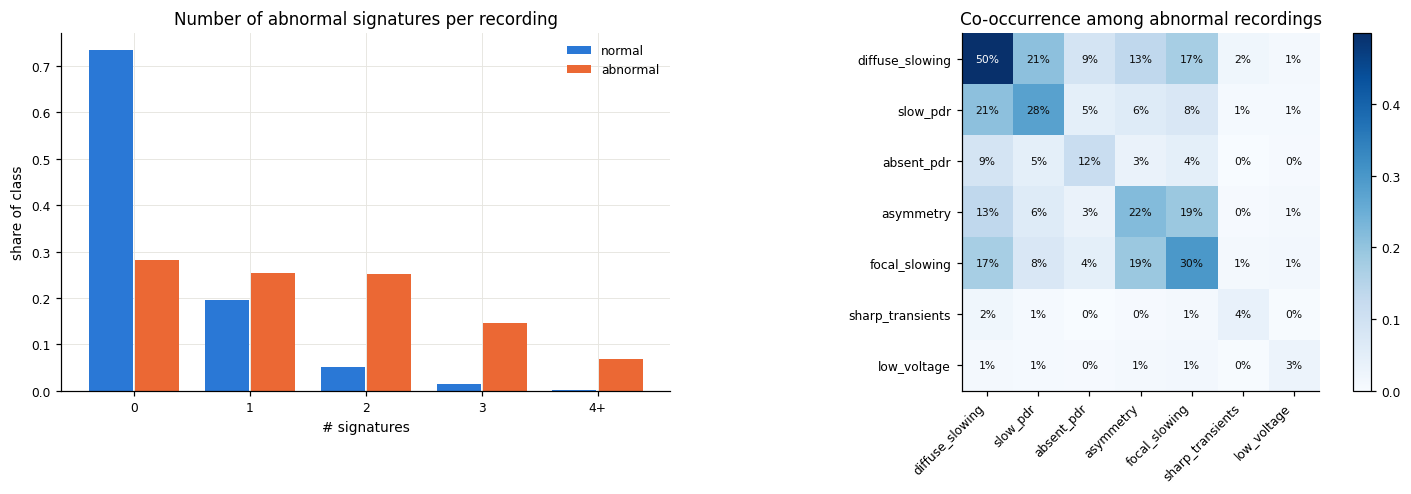

In [11]:
reference = (df["label"] == "normal") & (df["tuh_split"] == "train")
flags = signature_flags(df, reference)
prev = pd.DataFrame({
    lab: flags[df["label"] == lab].mean() for lab in ["normal", "abnormal"]
}).assign(lift=lambda t: t["abnormal"] / t["normal"].clip(lower=1e-3))
prev["feature"] = [SIGNATURES[s][0] for s in prev.index]
display(prev.sort_values("lift", ascending=False).style.format(
    {"normal": "{:.1%}", "abnormal": "{:.1%}", "lift": "x{:.1f}"}))

n_sig = flags.sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
t = pd.crosstab(n_sig.clip(upper=4), df["label"], normalize="columns")
x = np.arange(len(t))
for j, lab in enumerate(["normal", "abnormal"]):
    axes[0].bar(x + (j - 0.5) * 0.4, t[lab], width=0.38, color=CLASS_COLORS[lab], label=lab)
axes[0].set_xticks(x, [str(i) if i < 4 else "4+" for i in t.index])
axes[0].set(title="Number of abnormal signatures per recording", xlabel="# signatures",
            ylabel="share of class"); axes[0].legend()

ab = flags[df["label"] == "abnormal"]
co = (ab.T.astype(int) @ ab.astype(int)) / len(ab)
im = axes[1].imshow(co, cmap="Blues", vmin=0)
axes[1].set_xticks(range(len(co)), co.columns, rotation=45, ha="right")
axes[1].set_yticks(range(len(co)), co.index); axes[1].grid(False)
for i in range(len(co)):
    for j in range(len(co)):
        axes[1].text(j, i, f"{co.iloc[i, j]:.0%}", ha="center", va="center", fontsize=7,
                     color="white" if co.iloc[i, j] > co.values.max() * 0.6 else "#0b0b0b")
axes[1].set_title("Co-occurrence among abnormal recordings")
plt.colorbar(im, ax=axes[1], fraction=0.04); plt.tight_layout()
print(f"abnormal recordings with NO signature: {(n_sig[df.label == 'abnormal'] == 0).mean():.0%}  "
      f"(normals with none: {(n_sig[df.label == 'normal'] == 0).mean():.0%})")

In [12]:
# The dominant phenotype per abnormal recording = the signature it violates most strongly
# (largest exceedance in reference-SD units), for a readable "reason" column.
z = pd.DataFrame(index=df.index)
for name, (col, direction) in SIGNATURES.items():
    ref = df.loc[reference, col]
    s = (df[col] - ref.median()) / ref.std()
    z[name] = s if direction == "high" else -s
df["putative_reason"] = np.where(flags.any(axis=1), z.where(flags, -np.inf).idxmax(axis=1), "none detected")
reason = pd.crosstab(df["putative_reason"], df["label"])
reason = reason.loc[reason["abnormal"].sort_values(ascending=False).index]
display(reason.assign(**{"abnormal %": lambda t: 100 * t["abnormal"] / t["abnormal"].sum()}).round(1))

label,abnormal,normal,abnormal %
putative_reason,,,
diffuse_slowing,519,66,35.3
none detected,414,1117,28.1
focal_slowing,264,64,17.9
slow_pdr,117,43,7.9
asymmetry,76,63,5.2
sharp_transients,36,77,2.4
low_voltage,28,60,1.9
absent_pdr,18,31,1.2


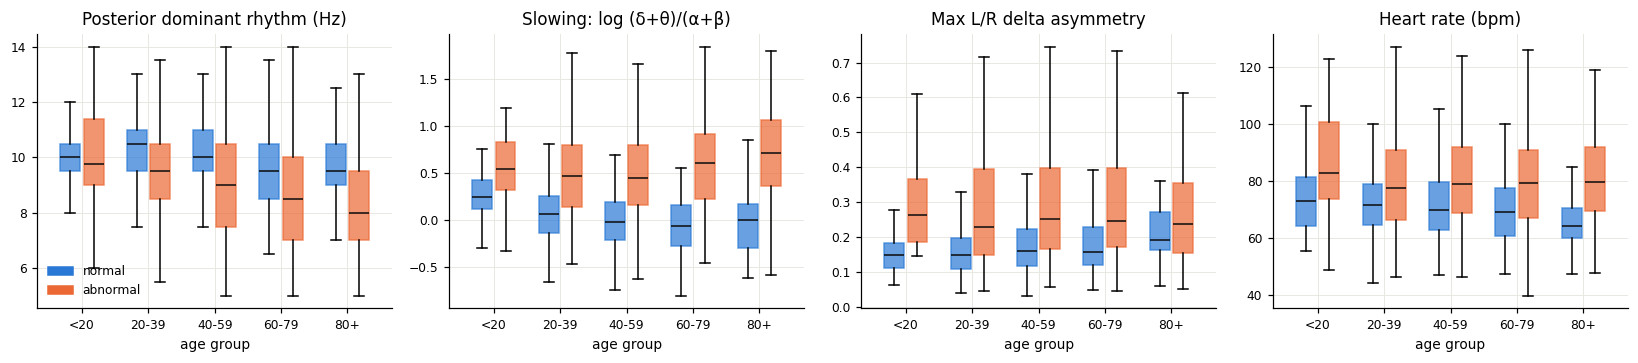

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (col, title) in zip(axes, [
    ("qeeg_pdr_freq", "Posterior dominant rhythm (Hz)"),
    ("qeeg_slowing_ratio", "Slowing: log (δ+θ)/(α+β)"),
    ("qeeg_max_delta_asymmetry", "Max L/R delta asymmetry"),
    ("ekg_hr_bpm", "Heart rate (bpm)"),
]):
    groups = df["age_group"].cat.categories
    pos = np.arange(len(groups))
    for j, lab in enumerate(["normal", "abnormal"]):
        data = [df.loc[(df.age_group == g) & (df.label == lab), col].dropna() for g in groups]
        bp = ax.boxplot(data, positions=pos + (j - 0.5) * 0.35, widths=0.3, showfliers=False,
                        patch_artist=True, medianprops=dict(color="#0b0b0b"))
        for b in bp["boxes"]:
            b.set(facecolor=CLASS_COLORS[lab], alpha=0.7, edgecolor=CLASS_COLORS[lab])
    ax.set_xticks(pos, groups); ax.set(title=title, xlabel="age group")
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=C_NORMAL), plt.Rectangle((0, 0), 1, 1, color=C_ABNORMAL)],
               ["normal", "abnormal"])
plt.tight_layout()

### Clinical-context hints hidden in the setup

TUAB has no referral reason, but some recording details are indirect evidence of *why* and
*in what state* the patient was recorded. Each row of the table below is one condition that
can be read off a recording:

| condition | how it is read | what it hints at |
|---|---|---|
| **sphenoidal electrodes** | SP1/SP2 channels exist in the EDF (`has_sphenoidal`) | Fine wire electrodes near the skull base reach the deep temporal lobe. They are placed when **temporal-lobe epilepsy** is suspected, i.e. in an epilepsy work-up. |
| **session number > 5** | the recording comes from the patient's 6th or later TUH EEG session (`session_number`, Section 2) | A patient recorded many times: **chronic neurological follow-up** (epilepsy, recurrent ICU stays). |
| **suppression > 50% for > 5% of record** | among recordings whose amplifier wrote the `SUPPR` trend channel, more than 5% of the seconds have a value above 50 (`trend_suppr_gt50_frac`, Eq. (5.12)) | *Expected*: sustained burst-suppression, i.e. an **ICU / encephalopathy / anaesthesia** context. *Observed*: the opposite (see below). |
| **photic stimulation done / not done** | the photic stimulator channel carried flashes (`photic_performed`, Eq. (5.11)) | Photic stimulation is a routine step of an outpatient EEG. Skipping it suggests a patient who **could not cooperate**: obtunded, sedated, ICU, or a short bedside recording. |

Columns (all over the 2,993 TUAB recordings):
* `recordings`: recordings that meet the condition.
* `abnormal_rate`: their abnormal rate $r(G)$, Eq. (2.1). For comparison, the base rate of
  all recordings is in the last row.
* `abnormal_rate_rest`: the abnormal rate of the recordings where the condition is known to be
  **false**. Recordings where it cannot be evaluated are left out: the suppression row compares
  only recordings *with* a `SUPPR` trend.
* `lift` = `abnormal_rate` / `abnormal_rate_rest`.
* `mean_age`: the mean age (years) of the recordings meeting the condition, since several
  conditions go with older patients.


In [14]:
has_trend = df["trend_suppr_gt50_frac"].notna()
# condition -> (recordings that meet it, recordings where it is known to be false)
ctx = {
    "sphenoidal electrodes": (df["has_sphenoidal"] == 1, df["has_sphenoidal"] == 0),
    "session number > 5": (df["session_number"] > 5, df["session_number"] <= 5),
    "suppression > 50% for > 5% of record": (has_trend & (df["trend_suppr_gt50_frac"] > 0.05),
                                             has_trend & (df["trend_suppr_gt50_frac"] <= 0.05)),
    "no SUPPR trend written at all": (~has_trend, has_trend),
    "photic stimulation done": (df["photic_performed"] == 1, df["photic_performed"] == 0),
    "no photic stimulation": (df["photic_performed"] == 0, df["photic_performed"] == 1),
    "all recordings (base rate)": (pd.Series(True, index=df.index), pd.Series(False, index=df.index)),
}
hints = pd.DataFrame({
    name: {"recordings": int(yes.sum()),
           "abnormal_rate": df.loc[yes, "is_abnormal"].mean(),                    # Eq. (2.1)
           "abnormal_rate_rest": df.loc[no, "is_abnormal"].mean() if no.any() else np.nan,
           "mean_age": df.loc[yes, "age"].mean()}
    for name, (yes, no) in ctx.items()}).T
hints["lift"] = hints["abnormal_rate"] / hints["abnormal_rate_rest"]
hints.style.format({"recordings": "{:,.0f}", "abnormal_rate": "{:.0%}", "abnormal_rate_rest": "{:.0%}",
                    "mean_age": "{:.1f}", "lift": "x{:.2f}"}, na_rep="–")


,recordings,abnormal_rate,abnormal_rate_rest,mean_age,lift
sphenoidal electrodes,105,63%,49%,49.1,x1.29
session number > 5,190,90%,46%,50.8,x1.94
suppression > 50% for > 5% of record,"1,319",25%,54%,47.1,x0.46
no SUPPR trend written at all,"1,187",74%,33%,51.2,x2.28
photic stimulation done,"2,156",37%,80%,46.8,x0.47
no photic stimulation,837,80%,37%,55.1,x2.15
all recordings (base rate),"2,993",49%,–,49.1,–


Reading the table, row by row:

* **Sphenoidal electrodes**: 63% abnormal vs 49% without them (×1.3), at the same mean age. An
  epilepsy work-up is more often read abnormal, but most of these patients are still normal
  between seizures.
* **Session number > 5**: **90%** abnormal vs 46%. Patients who keep coming back are
  chronically ill; the session number is a strong proxy for illness, not for brain activity.
* **Suppression > 50%**: only **25%** abnormal vs 54% for the other recordings with a trend.
  A sustained clinical burst-suppression pattern would be almost always abnormal, so this
  device trend cannot mean what its name says. Its median is 68% in normal vs 30% in abnormal
  recordings. Its semantics are unknown (perhaps the device's own "quiet EEG" measure), so it
  must not be read clinically.
* **No SUPPR trend written**: 74% abnormal. Whether the trend exists depends on the amplifier
  and software (Section 3), so this is a recording-room shortcut, not physiology.
* **Photic stimulation**: skipped in 837 recordings, **80%** of them abnormal and 8 years
  older on average, against 37% when it was done. This is the clearest workflow signal:
  a patient who could not do photic stimulation was usually sicker.

None of these are measurements of the brain. They are useful to **stratify the evaluation**
(does a model still separate normal from abnormal *within* photic yes/no?), but should not be
model inputs (Section 7).


## 6. Can the meta features be used for training or prediction?

**The idea.** LaBraM predicts normal vs abnormal from raw EEG windows. This section asks how
far one gets **without the raw EEG**: from the per-recording meta features of this notebook
alone (age, sex, setup, quality, heart rate, and the qEEG spectral summaries). The meta-feature
model is a separate, cheap classifier that is **never fed into LaBraM**. It serves three
purposes:

1. **A baseline LaBraM has to beat.** If 13 spectral numbers plus age already reach a given
   AUROC, LaBraM's raw-EEG model is only worth its cost above that.
2. **A shortcut detector.** If *acquisition* or *history* features alone predict the label,
   the label is entangled with the workflow (Sections 3 and 5), and a model can cheat.
3. **A guide to fusion.** Features that are legitimately known at prediction time and carry
   information LaBraM may miss (age, sex) are candidates to add to the model (Section 7).

Concretely: one row per **recording**, target $y = 1$ for abnormal. The model is trained on
the TUAB **train** recordings and evaluated on the official, subject-disjoint TUAB **eval**
recordings, once per feature group, so each group's contribution can be read separately.

Two questions:

1. **How much label information is in each feature on its own?** (univariate ROC-AUC on the
   training split, 0.5 = none)
2. **How well does metadata *alone* predict normal/abnormal?** Gradient-boosted trees trained
   on TUAB train, scored on the official, subject-disjoint TUAB eval set, one feature group at
   a time.

> **Comparing with LaBraM.** The published LaBraM-Base TUAB numbers (AUROC 0.902, balanced
> accuracy 0.814) are **per 10-s window**. The baselines here are **per recording**, which is an
> easier unit: a whole-recording statistic averages out noise that a single window cannot.
> For a like-for-like comparison, use the recording-level (case-aggregated) LaBraM metrics
> from `notebooks/finetune_evaluation.ipynb`.

**Metrics.** For a score $u_i$ (one feature, or the model's predicted probability $p_i$) and
labels $y_i$, the ROC-AUC is the probability that a random abnormal recording scores higher
than a random normal one (ties count half):
$$ \operatorname{AUC}(u) = \frac{1}{\lvert A\rvert\,\lvert N\rvert}\sum_{i \in A}\sum_{j \in N}\Big(\mathbb{1}[u_i > u_j] + \tfrac12\,\mathbb{1}[u_i = u_j]\Big). \tag{6.1} $$
The **univariate** AUC of a feature is oriented so that 0.5 = no information and 1 = perfect,
whichever direction separates (`labram/eval/meta_analysis.py::univariate_auc`; missing values
dropped per feature, `coverage` = share kept):
$$ \begin{aligned} \operatorname{AUC}_{\text{uni}}(x) &= \max\big(\operatorname{AUC}(x),\ 1 - \operatorname{AUC}(x)\big) \\ \text{direction} &= \begin{cases}\text{higher = abnormal} & \operatorname{AUC}(x) \ge 0.5\\ \text{lower = abnormal} & \text{else.}\end{cases} \end{aligned} \tag{6.2} $$
The metadata-only model (`metadata_baseline`: histogram gradient-boosted trees, 300
iterations, learning rate 0.05, 15 leaves, L2 = 1; NaNs handled natively) is scored by the
AUROC of $p_i$, Eq. (6.1), and by the balanced accuracy at threshold 0.5:
$$ \operatorname{BalAcc} = \frac12\left(\frac{\sum_{i \in A}\mathbb{1}[p_i \ge 0.5]}{\lvert A\rvert} + \frac{\sum_{i \in N}\mathbb{1}[p_i < 0.5]}{\lvert N\rvert}\right). \tag{6.3} $$
The **permutation importance** of feature $k$ is the drop in eval AUROC when its column is
shuffled, averaged over $R = 10$ shuffles $\pi_r$:
$$ \Delta_k = \operatorname{AUC}(p) - \frac1R\sum_{r=1}^{R}\operatorname{AUC}\big(p^{(k \leftarrow \pi_r)}\big). \tag{6.4} $$


,feature,group,auc,direction,coverage,median_normal,median_abnormal
0,qeeg_theta_alpha_ratio,qeeg,0.820,higher=abnormal,1.000,-0.230,0.201
1,qeeg_slowing_ratio,qeeg,0.813,higher=abnormal,1.000,0.020,0.518
2,qeeg_aperiodic_slope,qeeg,0.795,lower=abnormal,1.000,-1.273,-1.892
3,qeeg_rel_beta,qeeg,0.775,lower=abnormal,1.000,0.184,0.092
4,qeeg_rel_alpha,qeeg,0.774,lower=abnormal,1.000,0.255,0.119
5,qeeg_rel_delta,qeeg,0.751,higher=abnormal,1.000,0.353,0.551
6,qeeg_max_delta_asymmetry,qeeg,0.728,higher=abnormal,1.000,0.155,0.248
7,qeeg_log_total_power,qeeg,0.703,higher=abnormal,1.000,1.761,2.012
8,qeeg_pdr_freq,qeeg,0.688,lower=abnormal,1.000,10.000,9.000
9,session_number,history,0.685,higher=abnormal,1.000,1.000,2.000


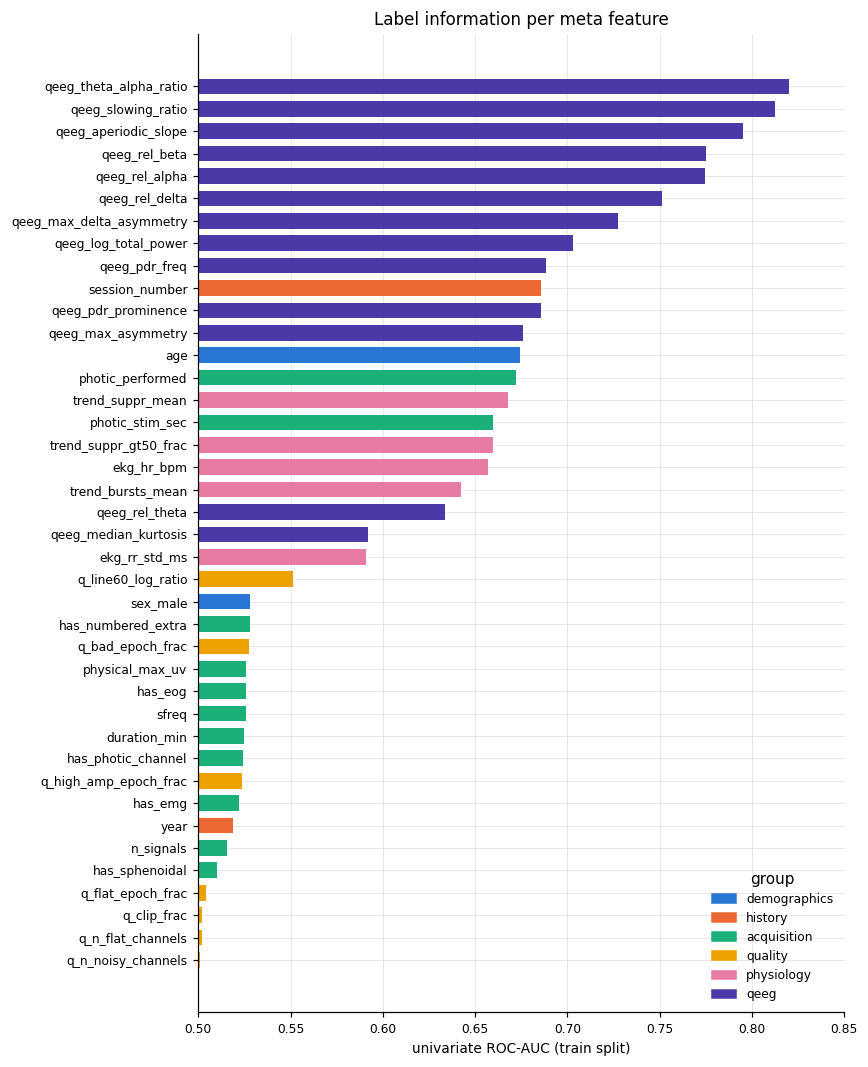

In [15]:
train = df[df.tuh_split == "train"]
test = df[df.tuh_split == "eval"]
uni = univariate_auc(train, available_features(df))
fig, ax = plt.subplots(figsize=(8, 0.22 * len(uni) + 1))
ax.barh(uni["feature"][::-1], uni["auc"][::-1] - 0.5, left=0.5,
        color=[GROUP_COLORS[g] for g in uni["group"][::-1]], height=0.7)
ax.axvline(0.5, color="#52514e", lw=1)
ax.set(xlim=(0.5, max(0.85, uni["auc"].max() + 0.02)), xlabel="univariate ROC-AUC (train split)",
       title="Label information per meta feature")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()], GROUP_COLORS.keys(),
          loc="lower right", title="group")
plt.tight_layout()
uni.head(15)

In [16]:
experiments = {
    "demographics (age, sex)": ["demographics"],
    "+ history (session no., year)": ["demographics", "history"],
    "acquisition only": ["acquisition"],
    "quality only": ["quality"],
    "physiology only (EKG, trends)": ["physiology"],
    "qEEG only": ["qeeg"],
    "demographics + qEEG": ["demographics", "qeeg"],
    "all meta features": list(FEATURE_GROUPS),
    "all except acquisition/history": ["demographics", "quality", "physiology", "qeeg"],
}
results, models = [], {}
for name, groups in experiments.items():
    feats = available_features(df, groups)
    m, model = metadata_baseline(train, test, feats)
    results.append({"features": name, **m}); models[name] = (model, feats)
res = pd.DataFrame(results).set_index("features")
display(res.style.format({"auroc": "{:.3f}", "balanced_acc": "{:.3f}"}).bar(
    subset=["auroc"], vmin=0.5, vmax=1.0, color="#a8c8ef"))

,auroc,balanced_acc,n_features
features,,,
"demographics (age, sex)",0.689,0.639,2
"+ history (session no., year)",0.727,0.644,4
acquisition only,0.686,0.658,11
quality only,0.574,0.575,7
"physiology only (EKG, trends)",0.783,0.721,5
qEEG only,0.890,0.813,13
demographics + qEEG,0.901,0.832,15
all meta features,0.922,0.863,40
all except acquisition/history,0.907,0.831,27


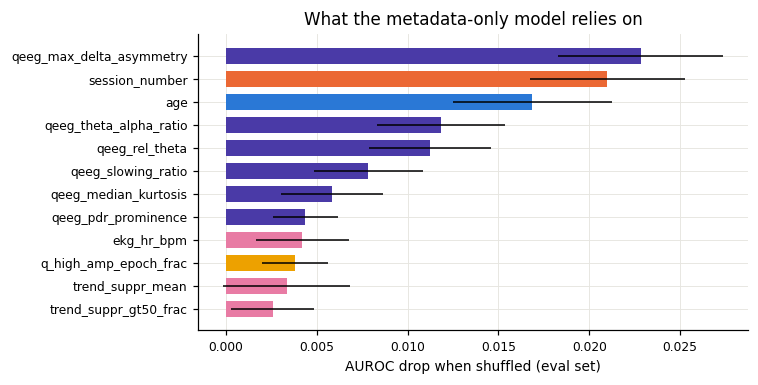

In [17]:
from sklearn.inspection import permutation_importance
model, feats = models["all meta features"]
pi = permutation_importance(model, test[feats].astype(float), test["is_abnormal"], scoring="roc_auc",
                            n_repeats=10, random_state=0)
imp = pd.DataFrame({"feature": feats, "auroc_drop": pi.importances_mean, "std": pi.importances_std}) \
        .sort_values("auroc_drop", ascending=False).head(12)
imp["group"] = [next(g for g, c in FEATURE_GROUPS.items() if f in c) for f in imp["feature"]]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(imp["feature"][::-1], imp["auroc_drop"][::-1], xerr=imp["std"][::-1],
        color=[GROUP_COLORS[g] for g in imp["group"][::-1]], height=0.7, error_kw=dict(lw=1))
ax.set(xlabel="AUROC drop when shuffled (eval set)", title="What the metadata-only model relies on")
plt.tight_layout()

### Relevance for the age-regression task

For the brain-age task (`TUAB_AGE`), the interesting question is the reverse: which meta
features *track age* — these are what a brain-age model will implicitly learn, and the
non-EEG ones (heart rate, session number) are covariates to control for. Spearman ρ within
**normal** recordings only, so pathology doesn't drive it, where Spearman's $\rho$ is the Pearson correlation of the ranks
$R(\cdot)$ (average ranks for ties), over the normal recordings with both values:
$$ \rho(x, a) = \frac{\operatorname{cov}\big(R(x), R(a)\big)}{\sigma_{R(x)}\,\sigma_{R(a)}}. \tag{6.5} $$


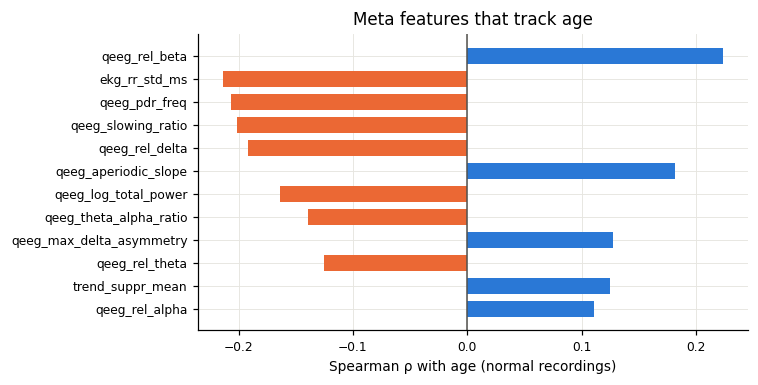

In [18]:
normals = df[df.label == "normal"]
feats = [f for f in available_features(df) if f != "age"]
rho = normals[feats + ["age"]].corr(method="spearman")["age"].drop("age").dropna()
rho = rho.reindex(rho.abs().sort_values(ascending=False).index).head(12)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(rho.index[::-1], rho.values[::-1], color=[C_NORMAL if v > 0 else C_ABNORMAL for v in rho.values[::-1]],
        height=0.7)
ax.axvline(0, color="#52514e", lw=1)
ax.set(xlabel="Spearman ρ with age (normal recordings)", title="Meta features that track age")
plt.tight_layout()

## 7. Findings and recommendations

Numbers are from the full TUAB v3.0.0 sweep (2,993 recordings, 2,329 subjects, 0 extraction failures).

### What meta information exists

| | coverage | note |
|---|---|---|
| Age | 99.5% | 15 unusable: 12 × `Age:999` (90+, redacted), 3 × `Age:0` |
| Sex | 100% | |
| Session number, recording year | 100% | year **1899** (16 recordings) and **2000** (29) are placeholder dates; treat as missing |
| Heart rate / HRV (EKG lead) | 100% | an EKG lead exists on every recording; R-peaks detected in all |
| Photic stimulation | 95% have the channel; performed in 72% | |
| Device burst-suppression trends | 60% | computed only by some acquisition systems |
| EMG / sphenoidal electrodes | 61% / 3.5% | |
| **Reason for abnormality, diagnosis, medication, vigilance** | **0%** | not distributed by TUH |

### Demographics

* Abnormal patients are **~10 years older** (mean 54.4 vs 44.0). The abnormal rate climbs from 31% (age 20–39) to 72% (80+).
* Sex is nearly balanced: 52% of male recordings are abnormal, vs 47% of female ones.
* 443 subjects have more than one recording, and **54 have both a normal and an abnormal one**.
* **Session number is a strong proxy for illness.** 36% of first EEGs are abnormal, rising to 81% at sessions 4–5 and 96% after more than 10 sessions.

### Data quality

* **The data is mostly clean.** Clipping is essentially absent, and the median recording has 1.4% artifact epochs. Quality tiers: **2,116 good / 791 fair / 86 poor**.
* **Poor quality concentrates in abnormal recordings.** Train has 64 poor abnormal recordings vs 15 poor normal ones; very ill and ICU patients produce more artifact.
* A handful of recordings are essentially unusable: 100% artifact epochs, or 6–8 dead electrodes (a few train recordings and one *eval* recording; cell 14 lists them when run locally). All of them are labelled abnormal, so every window they contribute teaches "noise = abnormal".
* **Mains noise is not removed.** `make_TUAB.py` notches 50 Hz, but TUH is US data with 60 Hz mains. In the processed training windows the 60 Hz peak is a median ×2.2 above the neighbouring floor, and over ×10 in 17% of recordings.
* 3 abnormal train EDFs never made it into the processed windows.

### Why is a case abnormal? (putative, from qEEG)

| signature | abnormal | normal |
|---|---|---|
| diffuse slowing | **50%** | 5% |
| focal (delta) asymmetry | **30%** | 5% |
| slow posterior rhythm | **28%** | 4% |
| hemispheric asymmetry | **22%** | 6% |
| absent posterior rhythm | 12% | 5% |
| sharp transients (kurtosis), low voltage | 3–4% | 5–6% (no signal) |

* **72% of abnormal recordings show at least one signature**, vs 27% of normals. Many show several: slowing and slow PDR co-occur, and so do focal slowing and asymmetry.
* **28% of abnormal recordings show none.** These are most likely epileptiform-only abnormalities (brief spikes that whole-recording spectra cannot see), subtle findings, or label noise. They should be the hardest cases for any model.
* The kurtosis "spike" proxy does **not** work: kurtosis is *higher* in normals, because it is dominated by eye blinks and alpha bursts. Recovering epileptiform reasons needs event annotations (TUEV) or a TUEV-trained detector.
* **Context hints:** recordings *without* photic stimulation are **80% abnormal** (837 recordings), vs 37% with it. Sphenoidal electrodes mean 63% abnormal. More than 5 sessions means 90% abnormal.
* The device `SUPPR` trend is *higher* in normals (median 68% vs 30%). It is therefore **not** a clinical burst-suppression percentage; its semantics are unknown, so do not interpret it clinically.

### Can the meta features be used? Metadata-only model, recording level, official eval set

| features | AUROC | bal. acc |
|---|---|---|
| demographics (age, sex) | 0.689 | 0.639 |
| + history (session number, year) | 0.727 | 0.644 |
| acquisition only | 0.686 | 0.658 |
| quality only | 0.574 | 0.575 |
| physiology only (EKG, trends) | 0.783 | 0.721 |
| **qEEG only** | **0.890** | **0.813** |
| demographics + qEEG | 0.901 | 0.832 |
| patient-level (all except acquisition/history) | 0.907 | 0.831 |
| all meta features | 0.922 | 0.863 |

13 hand-crafted spectral summaries plus age already recover most of the TUAB label. In practice the label mostly means "background slowing or asymmetry beyond what is normal for this age". That makes a **strong, cheap baseline** that LaBraM has to beat at the *recording* level.

### Recommendations

1. **Use age (and sex) as inputs.** They are legitimately known at prediction time, and normal EEG ranges are age-dependent. The simplest route is late fusion: concatenate them to the pooled embedding before the head, or stack them on the case-level LaBraM score.
2. **Run a stacking experiment:** a gradient-boosted model on LaBraM's recording-level probability + qEEG + age. If it beats LaBraM alone, the encoder is missing information. If not, LaBraM has already absorbed it.
3. **Do not feed acquisition/history features to the model** (photic performed, session number, device tags, trend availability, sampling rate). They encode Temple's referral workflow and will not transfer to another hospital. **Do use them to stratify evaluation**: check LaBraM within photic yes/no and first-session vs repeat subgroups. A large drop within strata means the model learned the workflow.
4. **Use the putative reasons for error analysis and auxiliary targets.** Measure recall per phenotype, especially on the 28% of abnormals with no signature. Regressing slowing ratio / PDR as an auxiliary head is a cheap multi-task regularizer.
5. **Clean the data.** Drop or down-weight the 86 poor-tier recordings, or mask their bad epochs. Add a 60 Hz notch: this needs a reprocessing pass, and should be checked against the pre-trained checkpoint, which saw the same 60 Hz residue. Treat years 1899/2000 as missing.
6. **To get real abnormality reasons,** request the annotated TUH subcorpora (TUEV events, TUSZ seizures, TUSL slowing, TUEP epilepsy, TUAR artifacts) and join them to TUAB by subject id. They are not on disk or in S3 today, and the id overlap still has to be verified once they are downloaded.

# Part II — the TUEG cohort (`all_both_v3`)

Part I describes TUAB: 2,993 recordings, a binary label and nothing else. The brain-age
models are now trained on a much larger TUH cohort, **`all_both_v3`**: 29,309 recordings of
13,801 patients aged 18–89. It holds every TUEG recording with the standard channels
(T1/T2 may be missing), plus the TUAB recordings. The patient-level split comes from
`dataset_maker/make_cohort_dataset.py`: TUAB patients keep their TUAB age split, the TUAB
eval set is the test set, and other TUEG patients follow the shared TUEG patient split.
Part II repeats the Part I questions on this cohort and adds one that TUAB cannot answer.
NEDC's clinical sheet gives diagnoses, medications and the report's own *reason* for an
abnormal read.

## 8. The cohort and its meta sources

TUEG is on local disk only as processed per-recording npy files; its 1.75 TB of EDFs
are in S3. The meta table is therefore built from the read-only sources in Table 8.1, not
from an EDF sweep:

```bash
python -m dataset_maker.make_cohort_meta \
    --cohort /data/datasets/EEG-public/TUH_EEG/cohorts/all_both_v3 --n_jobs 8
# -> <cohort>/meta_features.parquet  (~80 min on 8 cores, resumable)
```

### Table 8.1. Sources of TUEG meta information

| Source | Columns | Notes |
|---|---|---|
| cohort (`cohort.parquet`, `manifest.json`, `age_metadata.json`) | `split`, `age`, `sex`, `label`, `n_windows`, `duration_sec` | `label` = TUAB folder label if the recording is in TUAB, else the NEDC report (`abnormal due to` non-empty); none when neither exists |
| recording index (`dataset_maker/tuh_index.py`) | `session_number`, `year`, `montage`, `sfreq`, `missing_channels`, `corpora` | from the EDF headers, scanned while downloading |
| NEDC clinical sheet (`dataset_maker/tuh_clinical.py`) | `dx_*` (15 diagnoses), `med_*` (6 drug classes), `f_*` (FIRDA/OIRDA/TIRDA/GPD/LPD), `abnormal_due_to` | per session; **not in TUAB**; a session missing from the sheet has unknown (NaN) flags, never False |
| TUEG header dump (`DOCS/headers.tar.gz`, `tuh_meta_features.parse_header_dump`) | `equipment_family`, `physical_max_uv`, `has_ekg/emg/eog/photic_channel/sphenoidal/trend_channels` | the full EDF header of all 70,831 TUEG files, so no EDF has to be read |
| processed npy (`tuh_meta_features.npy_signal_features`) | `q_*` quality, `qeeg_*` | the same functions as Part I, on the 0.1–75 Hz, 200 Hz, 50/60 Hz-interpolated signal, first ≤ 60 min, recorded scalp channels only |

Part I's EKG, photic and burst-suppression *signal* features are missing here, because
those channels are not kept in the npy. Clipping and the mains ratio cannot be measured
after band-pass, resampling and line removal, so they are dropped too.

In [19]:
import os
from IPython.display import Markdown
from scipy.stats import spearmanr
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels
from labram.eval.meta_analysis import (
    COHORT_FEATURE_GROUPS, REASON_TO_SIGNATURE, metadata_age_baseline, report_reason_flags,
    signature_by_condition,
)

TUEG_META = Path("/data/datasets/EEG-public/TUH_EEG/cohorts/all_both_v3/meta_features.parquet")
CG = COHORT_FEATURE_GROUPS
LABELS = ["normal", "abnormal"]
COHORT_GROUP_COLORS = dict(zip(CG, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
                                     "#52514e", "#4a3aa7"]))


def finish(fig, axes=None):
    """House figure ending: layout, (a)/(b) panel letters, <= 2 panels per row."""
    fig.tight_layout()
    if axes is not None and len(np.ravel(axes)) > 1:
        panel_labels(axes)
    assert_max_columns(fig)
    plt.show()


tg = add_derived_columns(pd.read_parquet(TUEG_META))
tg["label3"] = tg["label"].fillna("unlabelled")
tg["year_clean"] = tg["year"].where(~tg["year"].isin([1899, 2000]))   # placeholder dates, as in Part I
labelled = tg["is_abnormal"].notna()
print(f"{len(tg):,} recordings, {tg['subject'].nunique():,} subjects, {tg.shape[1]} columns; "
      f"signal-feature failures: {(tg['signal_error'].fillna('') != '').sum()}, "
      f"not in the header dump: {(~tg['in_header_dump']).sum()}, "
      f"not in the clinical sheet: {(~tg['in_sheet']).sum():,}")

29,309 recordings, 13,801 subjects, 110 columns; signal-feature failures: 0, not in the header dump: 0, not in the clinical sheet: 2,490


### Table 8.2. Recordings per split and label

Recordings (subjects in the last column) of `all_both_v3` by split and label. *Unlabelled*
recordings are TUEG sessions that are neither in TUAB nor in the clinical sheet.
They train the age model but take no part in any normal/abnormal statistic below.

In [20]:
t82 = pd.crosstab(tg["split"], tg["label3"], margins=True, margins_name="all")
t82 = t82[["normal", "abnormal", "unlabelled", "all"]].reindex(["train", "val", "test", "all"])
t82["subjects"] = [tg.loc[tg["split"] == s, "subject"].nunique() if s != "all" else tg["subject"].nunique()
                   for s in t82.index]
t82["from TUAB"] = [tg.loc[tg["split"] == s, "in_tuab"].sum() if s != "all" else tg["in_tuab"].sum()
                    for s in t82.index]
display(numbered_table(t82, "8.2", "Recordings per split and label", precision=0))

label3,normal,abnormal,unlabelled,all,subjects,from TUAB
split,,,,,,
train,10067,13714,1832,25613,12017,1868
val,1388,1676,358,3422,1533,482
test,149,125,0,274,251,274
all,11604,15515,2190,29309,13801,2624


### Table 8.3. Coverage of the meta features, TUEG cohort vs TUAB

For every feature of the cohort groups (`labram/eval/meta_analysis.py::COHORT_FEATURE_GROUPS`),
the coverage is the share of recordings with a value,

$$ \operatorname{cov}(x) = \frac{1}{N}\sum_{i=1}^{N} \mathbb{1}\left[x_i \text{ not missing}\right], \tag{8.1} $$

over the $N$ recordings of the cohort (`TUEG %`) and of Part I's TUAB table (`TUAB %`; "–"
means the column does not exist there). `type`, `n_categories`, `categories` (the 5 most
frequent values with their share), `active_range` (1st–99th percentile) and `meaning` (for the
history, acquisition and qEEG groups) are defined as in Section 1.

In [21]:
t83 = feature_inventory(tg, CG).rename(columns={"coverage_%": "TUEG %"})        # Eq. (8.1)
t83.insert(4, "TUAB %", [100 * df[c].notna().mean() if c in df else np.nan for c in t83["feature"]])
t83 = t83.set_index(["group", "feature"])
display(numbered_table(t83.style.format({"TUEG %": "{:.1f}", "TUAB %": "{:.1f}", "n_categories": "{:.0f}"},
                                        na_rep="–"), "8.3", "Coverage of the meta features"))

Table 8.3 shows what the larger cohort adds and loses. The clinical sheet covers 91.5% of
recordings. TUAB has no counterpart at all for its 21 diagnosis and drug-class flags and
5 report findings. The header features (setup, channel inventory, history) are complete.
The signal features are complete except for 2 recordings whose electrodes all carry the
same trace (Section 11). The EKG lead is present in every header, but its signal is not in
the npy, so Part I's heart-rate features have no TUEG column.

## 9. Demographics and history

The abnormal rate of a group $G$ of labelled recordings, with $y_i = 1$ for abnormal, is

$$ r(G) = \frac{1}{\lvert G\rvert}\sum_{i \in G} y_i . \tag{9.1} $$

### Table 9.1. Age by label

Age (years) of the cohort recordings per label (all splits).

In [22]:
t91 = tg.groupby("label3")["age"].describe()[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
display(numbered_table(t91.reindex(["normal", "abnormal", "unlabelled"]), "9.1", "Age by label", precision=1))

,count,mean,std,min,25%,50%,75%,max
label3,,,,,,,,
normal,11604.0,48.3,17.1,18.0,34.0,48.0,61.0,89.0
abnormal,15515.0,55.5,17.2,11.0,44.0,57.0,68.0,89.0
unlabelled,2190.0,51.8,16.9,18.0,40.0,53.0,64.0,89.0


### Figure 9.1. Age, sex and the abnormal rate

(a) Age histogram (5-year bins, density) of normal, abnormal and unlabelled recordings.
(b) Abnormal rate, Eq. (9.1), per age group in the TUEG cohort (bars, with $n$), and in
TUAB (Part I, black markers). Labelled recordings of all splits: $n$ = 27,119 TUEG and
2,993 TUAB.

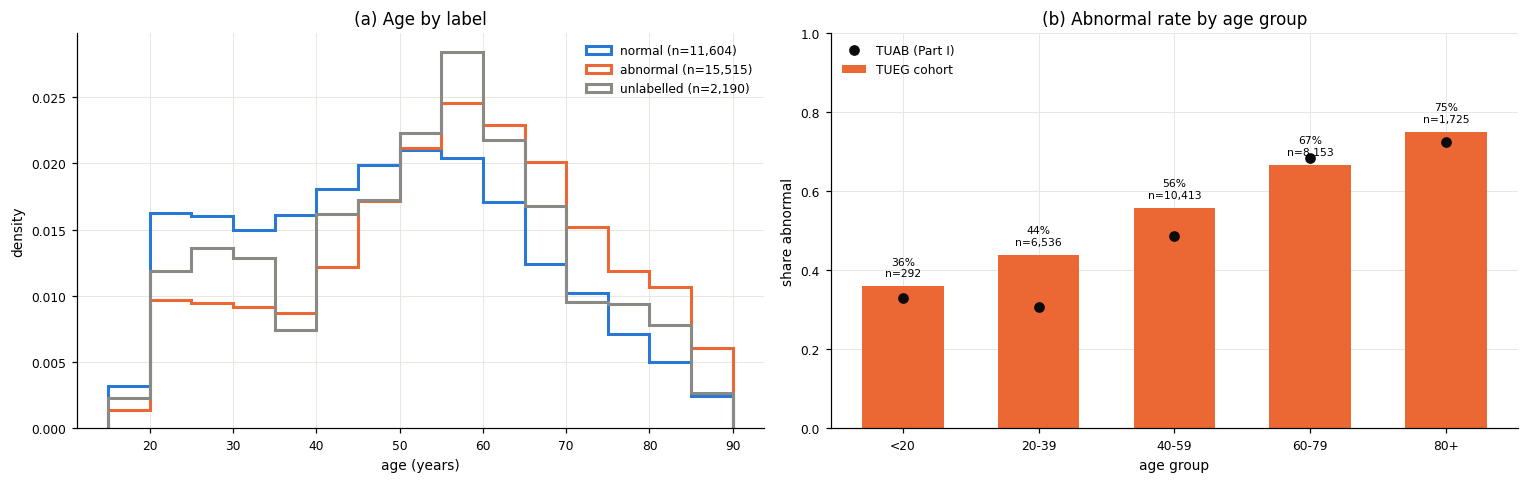

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.arange(15, 95, 5)
for lab, color in [("normal", C_NORMAL), ("abnormal", C_ABNORMAL), ("unlabelled", C_NEUTRAL)]:
    axes[0].hist(tg.loc[tg["label3"] == lab, "age"], bins=bins, histtype="step", lw=2, density=True,
                 color=color, label=f"{lab} (n={(tg['label3'] == lab).sum():,})")
axes[0].set(title="Age by label", xlabel="age (years)", ylabel="density"); axes[0].legend()

rate = tg[labelled].groupby("age_group", observed=True)["is_abnormal"].agg(["mean", "size"])   # Eq. (9.1)
rate_tuab = df.groupby("age_group", observed=True)["is_abnormal"].mean()
x = np.arange(len(rate))
axes[1].bar(x, rate["mean"], color=C_ABNORMAL, width=0.6, label="TUEG cohort")
axes[1].plot(x, rate_tuab.reindex(rate.index).to_numpy(), "o", color="#0b0b0b", label="TUAB (Part I)")
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    axes[1].text(i, m + 0.02, f"{m:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=7)
axes[1].set_xticks(x, rate.index.astype(str))
axes[1].set(title="Abnormal rate by age group", xlabel="age group", ylabel="share abnormal", ylim=(0, 1))
axes[1].legend(loc="upper left")
finish(fig, axes)

### Table 9.2. Abnormal rate by sex, session number and recording year

Labelled recordings: count and abnormal rate, Eq. (9.1), per value. The session number says
*which* TUH EEG session of the patient the recording is from (date order, whole TUH archive),
not how many sessions the patient has; see Section 2. Years 1899 and 2000 are the placeholder dates noted in Part I.

In [24]:
lab_tg = tg[labelled]
parts = {
    "sex": lab_tg["sex"],
    "session number": pd.cut(lab_tg["session_number"], [0, 1, 2, 3, 5, 10, 1000],
                             labels=["1", "2", "3", "4-5", "6-10", ">10"]).astype(str),
    "year": lab_tg["year"].astype(int).astype(str),
}
rows = []
for name, key in parts.items():
    for val, g in lab_tg.groupby(key, observed=True):
        rows.append({"variable": name, "value": val, "recordings": len(g), "abnormal rate": g["is_abnormal"].mean()})
t92 = pd.DataFrame(rows).set_index(["variable", "value"])
display(numbered_table(t92.style.format({"recordings": "{:,}", "abnormal rate": "{:.0%}"}), "9.2",
                       "Abnormal rate by sex, session and year"))

Two TUAB demographics findings carry over and one does not (Figure 9.1, Table 9.2). Abnormal
patients are again older, and the abnormal rate rises with age. In the cohort, though, the
rate is higher in every age group, because TUEG is mostly abnormal: the 2017 TUAB release
was balanced on purpose. Unlike TUAB, the session number is only weakly informative here:
55% of first sessions are abnormal against 54–64% later. TUAB's normal recordings were
selected mostly from first sessions, which made the session number look like a strong
proxy there. The abnormal rate is flat over 2004–2016 but drops to 4–9% in **2002–2003**,
so the early recordings come from a different referral population or reporting standard
(Section 10).

## 10. Acquisition setup: a shortcut for the label *and* for age

A setup variable is a shortcut when its value predicts the target without any brain
activity. For normal/abnormal that is an abnormal rate, Eq. (9.1), that differs between its
values. For brain age it is a mean age that differs between them. For a categorical variable
with levels $k = 1..K$, $n_k$ recordings and mean age $\bar a_k$ per level, the share of the age
variance it explains (one-way $\eta^2$) and the spread of the abnormal rate are

$$ \eta^2_{\text{age}} = \frac{\sum_{k} n_k\,(\bar a_k - \bar a)^2}{\sum_{i}(a_i - \bar a)^2}, \tag{10.1} $$

$$ \Delta r = \max_{k:\,n_k \ge 100} r(G_k) - \min_{k:\,n_k \ge 100} r(G_k), \tag{10.2} $$

where $a_i$ is the age (years) of recording $i$, $\bar a$ the cohort mean and $G_k$ the
labelled recordings at level $k$. Levels with fewer than 100 recordings are left out of
Eq. (10.2), so tiny groups do not set the range.

### Table 10.1. Shortcut strength of each setup variable

`eta2_age` is Eq. (10.1) over all recordings, `delta_abnormal_rate` is Eq. (10.2), and
`levels` counts the values of the variable. Recording year and session number are binned as
in Table 9.2, and the native sampling rate is taken as categorical.

In [25]:
def eta_squared(values, groups):
    """Eq. (10.1): between-level share of the variance of `values`."""
    d = pd.DataFrame({"v": values, "g": groups}).dropna()
    grand = d["v"].mean()
    between = d.groupby("g", observed=True)["v"].agg(["size", "mean"])
    return float((between["size"] * (between["mean"] - grand) ** 2).sum() / ((d["v"] - grand) ** 2).sum())


setup = {
    "amplifier family": tg["equipment_family"],
    "recording year": tg["year"].astype(str),
    "montage": tg["montage"],
    "native sampling rate": tg["sfreq"].astype(str),
    "amplifier range (uV)": tg["physical_max_uv"].round(0).astype(str),
    "T1/T2 missing": tg["n_missing_channels"] > 0,
    "photic channel": tg["has_photic_channel"],
    "sphenoidal electrodes": tg["has_sphenoidal"],
    "EMG channel": tg["has_emg"],
    "EOG (LOC/ROC)": tg["has_eog"],
    "trend channels": tg["has_trend_channels"],
    "session number": pd.cut(tg["session_number"], [0, 1, 2, 3, 5, 10, 1000]).astype(str),
}
rows = []
for name, key in setup.items():
    rate_k = tg[labelled].groupby(key[labelled], observed=True)["is_abnormal"].agg(["mean", "size"])
    big = rate_k[rate_k["size"] >= 100]["mean"]
    rows.append({"variable": name, "levels": key.nunique(),
                 "eta2_age": eta_squared(tg["age"], key),                      # Eq. (10.1)
                 "delta_abnormal_rate": big.max() - big.min()})                # Eq. (10.2)
t101 = pd.DataFrame(rows).set_index("variable").sort_values("eta2_age", ascending=False)
display(numbered_table(t101.style.format({"eta2_age": "{:.3f}", "delta_abnormal_rate": "{:.0%}"}), "10.1",
                       "Shortcut strength of each setup variable"))

,levels,eta2_age,delta_abnormal_rate
variable,,,
recording year,19,0.011,59%
amplifier family,6,0.005,58%
session number,6,0.004,10%
montage,3,0.004,3%
native sampling rate,5,0.004,56%
trend channels,2,0.004,4%
T1/T2 missing,2,0.003,7%
amplifier range (uV),3,0.003,55%
sphenoidal electrodes,2,0.002,10%


### Table 10.2. Amplifier families

Recordings, abnormal rate (Eq. (9.1)), mean age (years), median recording year and share in
the validation split per amplifier family. The family is the EDF `lrci_machine` tag
(`unknown` = anonymised or unset tag).

In [26]:
t102 = tg.groupby("equipment_family").agg(
    recordings=("stem", "size"), abnormal_rate=("is_abnormal", "mean"), mean_age=("age", "mean"),
    median_year=("year_clean", "median"), sfreq_mode=("sfreq", lambda s: s.mode().iat[0]),
    val_share=("split", lambda s: (s == "val").mean()),
).sort_values("recordings", ascending=False)
display(numbered_table(t102.style.format({"recordings": "{:,}", "abnormal_rate": "{:.0%}", "mean_age": "{:.1f}",
                                          "median_year": "{:.0f}", "sfreq_mode": "{:.0f}", "val_share": "{:.0%}"}),
                       "10.2", "Amplifier families"))

,recordings,abnormal_rate,mean_age,median_year,sfreq_mode,val_share
equipment_family,,,,,,
unknown,"16,774",58%,51.7,2014,250,13%
Intution/Ultrasom,"5,750",63%,54.5,2008,250,11%
Alliance,"3,035",41%,53.2,2004,250,10%
Compact_32ch,"2,170",64%,52.4,2015,256,10%
Compact_64ch,"1,406",58%,50.0,2015,256,12%
Bravo,174,7%,47.5,2003,400,13%


### Figure 10.1. Recording era and amplifier

(a) Recordings per year by amplifier family (stacked; placeholder years 1899/2000 left out).
(b) Mean age (years) per recording year, normal and abnormal recordings separately. TUEG
cohort, all splits.

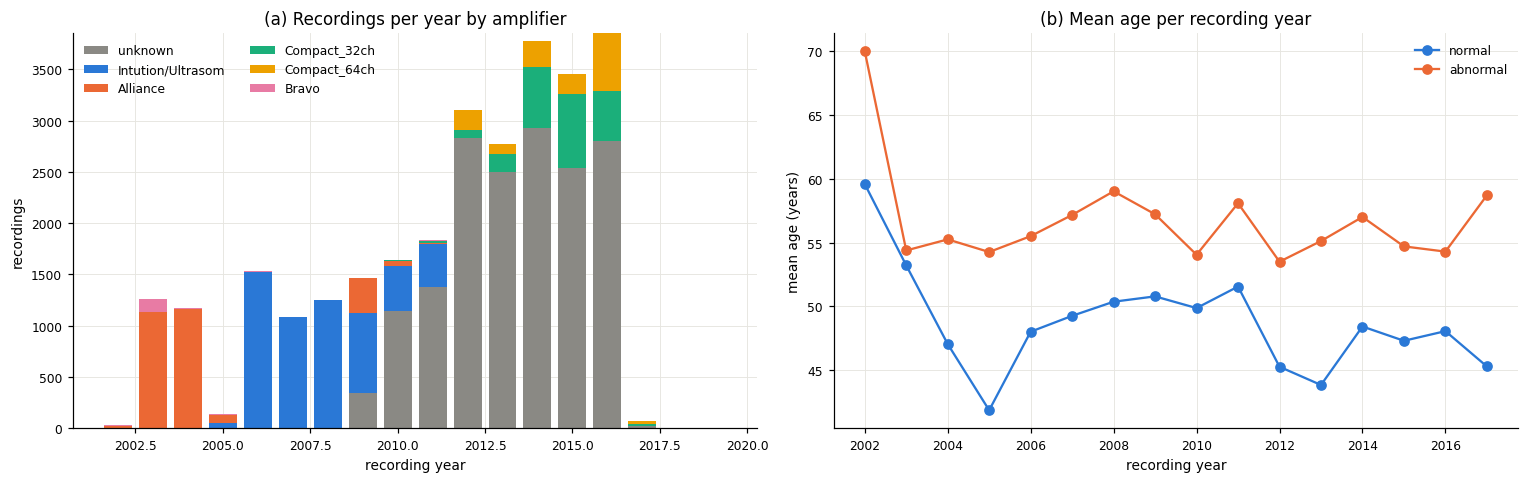

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
fam = pd.crosstab(tg["year_clean"], tg["equipment_family"])
fam = fam[t102.index]
bottom = np.zeros(len(fam))
palette = ["#8a8984", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
for color, col in zip(palette, fam.columns):
    axes[0].bar(fam.index.astype(int), fam[col], bottom=bottom, color=color, width=0.8, label=col)
    bottom += fam[col].to_numpy()
axes[0].set(title="Recordings per year by amplifier", xlabel="recording year", ylabel="recordings")
axes[0].legend(ncol=2)
for lab, color in [("normal", C_NORMAL), ("abnormal", C_ABNORMAL)]:
    m = tg[tg["label"] == lab].groupby("year_clean")["age"].mean()
    axes[1].plot(m.index.astype(int), m.values, "o-", color=color, label=lab)
axes[1].set(title="Mean age per recording year", xlabel="recording year", ylabel="mean age (years)")
axes[1].legend()
finish(fig, axes)

Table 10.1, Table 10.2 and Figure 10.1 show that the setup matters for the label but not for age.

**For the label**, the recording year and the amplifier are the strongest shortcuts: the
abnormal rate varies by 58–59 percentage points across their values. One amplifier family
(Bravo: 400 Hz sampling rate and a ±29,483 µV range, 2002–2003 only, 174 recordings) is
**7% abnormal**, and all recordings from 2002–2003 are only 4–9% abnormal, against 54–68% in
every later year. Its sampling rate and amplitude range leave a fingerprint even after
resampling, so a model can learn "this amplifier = normal".

**For age**, no setup variable explains more than 1.1% of the age variance (the recording
year, Eq. (10.1)). Even the shift from linked-ears (`02_tcp_le`, median year 2006) to average
reference (`01_tcp_ar`, median year 2014) comes with only a 2.4-year difference in mean age.
The cohort therefore offers no strong setup shortcut for brain age; Table 14.3 confirms this
from the model side.

## 11. Signal quality of the training data

These are the Part I quality measures (`labram/data/tuh_meta_features.py::quality_features`),
here computed on the processed npy the model actually reads. With $E$ 10-s epochs and the
recorded scalp channels $c$ (zero-filled channels are excluded), after a 0.5–45 Hz band-pass:

$$ b = \frac{1}{E}\sum_{e=1}^{E} \mathbb{1}\Big[\exists c:\ \sigma_{ec} < 0.5\,\mu\text{V}\ \vee\ \operatorname{ptp}_{ec} > 500\,\mu\text{V}\Big], \tag{11.1} $$

where $\sigma_{ec}$ and $\operatorname{ptp}_{ec}$ are the standard deviation and peak-to-peak
range of channel $c$ in epoch $e$. A channel is *flat* when $\sigma_{ec} < 0.5\,\mu$V in more
than half of the epochs. It is *noisy* when its log standard deviation over the whole
recording is a robust outlier among the recording's channels:

$$ \frac{\lvert \log \sigma_c - \operatorname{med}_{c'} \log \sigma_{c'} \rvert}{1.4826\,\operatorname{MAD}_{c'}(\log \sigma_{c'})} > 5 . \tag{11.2} $$

The quality tier is the Part I rule without its clipping criterion (clipping cannot be
measured after preprocessing): *poor* if $\ge 2$ flat channels or $b > 0.3$; else *fair* if
$\ge 1$ flat or noisy channel or $b > 0.1$; else *good*.

### Figure 11.1. Artifact load per recording

(a) Bad-epoch fraction $b$, Eq. (11.1), per recording by label (log count axis). (b) Flat +
noisy electrodes per recording, Eq. (11.2), by label (log axis). TUEG cohort, all splits.

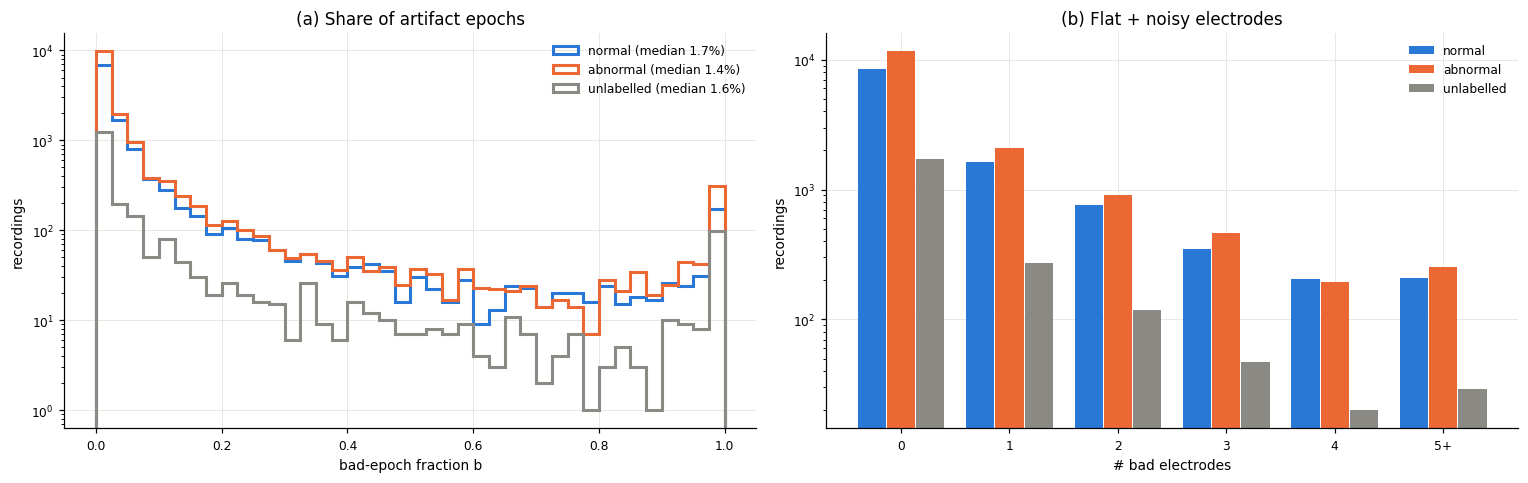

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lab, color in [("normal", C_NORMAL), ("abnormal", C_ABNORMAL), ("unlabelled", C_NEUTRAL)]:
    s = tg.loc[tg["label3"] == lab, "q_bad_epoch_frac"]                         # Eq. (11.1)
    axes[0].hist(s, bins=np.linspace(0, 1, 41), histtype="step", lw=2, color=color,
                 label=f"{lab} (median {s.median():.1%})")
axes[0].set(title="Share of artifact epochs", xlabel="bad-epoch fraction b", ylabel="recordings", yscale="log")
axes[0].legend()
bad_ch = (tg["q_n_flat_channels"] + tg["q_n_noisy_channels"]).clip(upper=5)   # Eq. (11.2)
t = pd.crosstab(bad_ch, tg["label3"])
x = np.arange(len(t))
for j, (lab, color) in enumerate([("normal", C_NORMAL), ("abnormal", C_ABNORMAL), ("unlabelled", C_NEUTRAL)]):
    axes[1].bar(x + (j - 1) * 0.27, t[lab], width=0.26, color=color, label=lab)
axes[1].set_xticks(x, [str(int(i)) if i < 5 else "5+" for i in t.index])
axes[1].set(title="Flat + noisy electrodes", xlabel="# bad electrodes", ylabel="recordings", yscale="log")
axes[1].legend()
finish(fig, axes)

### Table 11.1. Quality tiers by split and label

Recordings per quality tier (rule above), with the share of the row in parentheses, for the
TUEG cohort. The last row is TUAB from Part I. It is not directly comparable, because there
the tier was measured on the raw EDF and also counts clipping.

In [29]:
def tier_npy(r):
    if r.q_n_flat_channels >= 2 or r.q_bad_epoch_frac > 0.3:
        return "poor"
    if r.q_n_flat_channels + r.q_n_noisy_channels >= 1 or r.q_bad_epoch_frac > 0.1:
        return "fair"
    return "good"


tg["quality_tier"] = tg.apply(tier_npy, axis=1)
t111 = pd.crosstab([tg["split"], tg["label3"]], tg["quality_tier"])[["good", "fair", "poor"]]
t111.loc[("TUAB (Part I)", "all"), :] = df["quality_tier"].value_counts().reindex(["good", "fair", "poor"]).to_numpy()
t111 = t111.astype(int)
shares = t111.div(t111.sum(axis=1), axis=0)
display(numbered_table(t111.astype(str) + " (" + (100 * shares).round(0).astype(int).astype(str) + "%)",
                       "11.1", "Quality tiers by split and label"))
# Every scalp electrode carrying the same trace: the common average leaves no signal, so
# the qEEG features are NaN (qeeg_features) although no electrode is flat.
identical = tg["qeeg_log_total_power"].isna() & (tg["signal_error"].fillna("") == "")
print(f"recordings whose scalp channels are all identical: {identical.sum()} "
      f"(splits: {tg.loc[identical, 'split'].value_counts().to_dict()})")

recordings whose scalp channels are all identical: 2 (splits: {'train': 2})


Table 11.1 and Figure 11.1 differ from TUAB in two ways.

* **More artifact.** 7–8% of the labelled train and val recordings are *poor*, against 3% in
  TUAB, even though clipping is no longer counted here. TUEG keeps long ICU and ambulatory
  recordings that the curated TUAB set does not have (median duration 20 min, but up to
  24 h; the first 60 min are analysed).
* **Not label-dependent.** Poor quality hits normal and abnormal recordings alike (8% vs 7%
  in train). The *unlabelled* recordings, those not in the clinical sheet, are the worst:
  14% poor.

**Two train recordings are corrupt**: all 19 scalp electrodes carry the identical trace.
No electrode is flat, so the quality measures above do not catch them. Only the common
average gives them away, because it leaves no signal at all (their qEEG features are NaN).
They should be dropped from the brain-age training split.

## 12. Clinical context from the NEDC sheet

None of this exists for TUAB. For a flag $d$ (diagnosis or drug class) over the labelled
recordings of sessions in the sheet, with $D$ the recordings where $d$ is true and
$\bar D$ the rest:

$$ \operatorname{prev}(d) = \frac{\lvert D\rvert}{\lvert D\rvert + \lvert \bar D\rvert}, \qquad \Delta_{\text{age}}(d) = \bar a(D) - \bar a(\bar D), \tag{12.1} $$

with $\bar a$ the mean age in years. The abnormal rates $r(D)$ and $r(\bar D)$ follow
Eq. (9.1). Drug classes come from token matching of the medication list
(`dataset_maker/tuh_clinical.py::DRUG_CLASSES`). *Sedated* = anaesthetic, benzodiazepine,
barbiturate or opioid. Diagnoses are the sheet's Y/N columns.

### Table 12.1. Diagnoses and medication classes

One row per flag with at least 30 positive recordings: recordings and patients with the flag,
`prev` and `delta_age`, Eq. (12.1), and the abnormal rate with and without it. Sorted by
recordings.

In [30]:
in_sheet = tg[tg["in_sheet"] & labelled]
rows = []
for c in CG["clinical"] + ["any_neuro_dx", "sedated"]:
    flag = in_sheet[c].astype(float) == 1
    if flag.sum() < 30:
        continue
    rows.append({"flag": c, "recordings": int(flag.sum()), "patients": in_sheet.loc[flag, "subject"].nunique(),
                 "prev": flag.mean(),                                                          # Eq. (12.1)
                 "delta_age": in_sheet.loc[flag, "age"].mean() - in_sheet.loc[~flag, "age"].mean(),
                 "abnormal_with": in_sheet.loc[flag, "is_abnormal"].mean(),                   # Eq. (9.1)
                 "abnormal_without": in_sheet.loc[~flag, "is_abnormal"].mean()})
t121 = pd.DataFrame(rows).set_index("flag").sort_values("recordings", ascending=False)
display(numbered_table(t121.style.format({"recordings": "{:,}", "patients": "{:,}", "prev": "{:.1%}",
                                          "delta_age": "{:+.1f}", "abnormal_with": "{:.0%}",
                                          "abnormal_without": "{:.0%}"}),
                       "12.1", "Diagnoses and medication classes"))

,recordings,patients,prev,delta_age,abnormal_with,abnormal_without
flag,,,,,,
med_antiseizure,"13,533","6,293",50.5%,-3.4,62%,51%
sedated,"8,816","4,282",32.9%,+0.8,62%,54%
med_benzodiazepine,"5,889","2,827",22.0%,+0.0,61%,56%
med_opioid,"3,534","1,924",13.2%,+2.5,56%,57%
any_neuro_dx,"3,392","1,583",12.6%,-0.6,65%,56%
dx_clinical_seizure,"2,067",999,7.7%,-4.6,58%,57%
med_anesthetic,"1,507",466,5.6%,+5.4,52%,57%
med_antipsychotic,"1,177",761,4.4%,-1.3,63%,57%
dx_substance,"1,166",677,4.3%,-4.8,71%,56%


### Table 12.2. TUAB folder label vs NEDC report

The cohort's TUAB recordings that are also in the clinical sheet: the TUAB folder label
(rows) against the sheet's `abnormal due to` field being non-empty (columns). The agreement
is the diagonal share.

In [31]:
both = tg[tg["abnormal"].notna() & tg["in_sheet"]]
t122 = pd.crosstab(both["abnormal"].map({0: "TUAB normal", 1: "TUAB abnormal"}),
                   both["abnormal_report"].astype(float).map({0: "report normal", 1: "report abnormal"}))
agree = (both["abnormal"].astype(int) == both["abnormal_report"].astype(float)).mean()
display(numbered_table(t122, "12.2", "TUAB folder label vs NEDC report", precision=0))
print(f"agreement: {agree:.1%} of {len(both):,} recordings")

abnormal_report,report abnormal,report normal
abnormal,,
TUAB abnormal,903,79
TUAB normal,26,1316


agreement: 95.5% of 2,324 recordings


### Figure 12.1. Who are the patients?

(a) Prevalence, Eq. (12.1), of the most frequent diagnoses per age group (labelled recordings
in the sheet). (b) Prevalence of each medication class in normal vs abnormal recordings.
TUEG cohort, all splits; $n$ = 26,819 labelled recordings in the sheet.

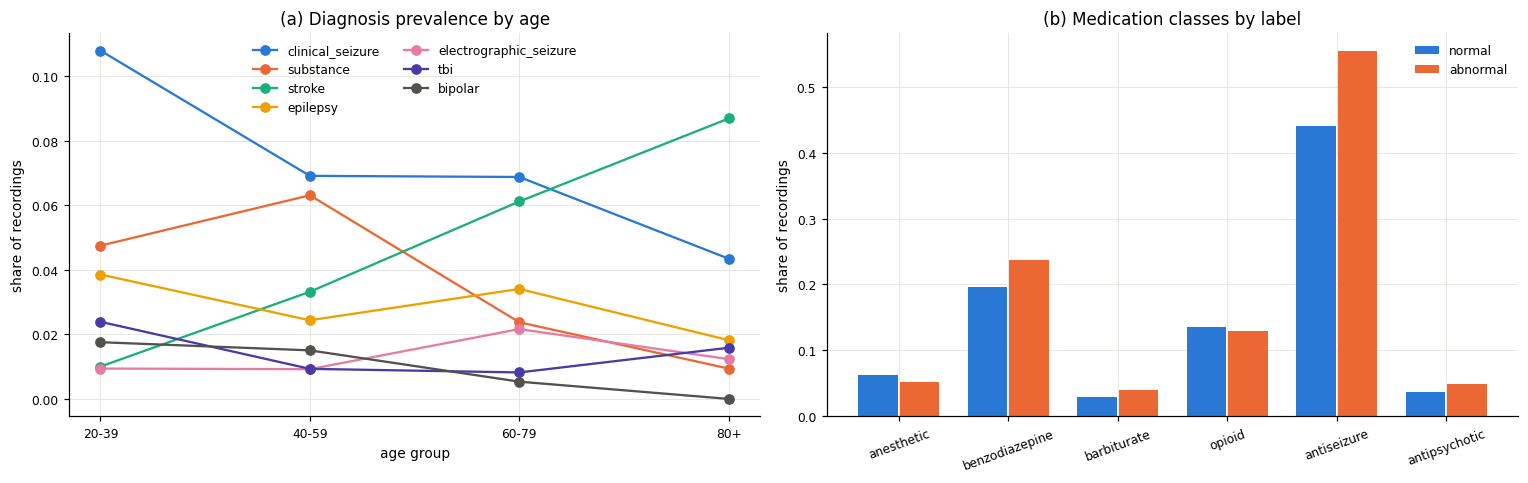

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
show = ["dx_clinical_seizure", "dx_substance", "dx_stroke", "dx_epilepsy", "dx_electrographic_seizure",
        "dx_tbi", "dx_bipolar"]
groups = in_sheet["age_group"].cat.categories[1:]                # < 20 is almost empty (cohort is 18-89)
for c, color in zip(show, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7", "#52514e"]):
    p = in_sheet.groupby("age_group", observed=True)[c].mean().reindex(groups)
    axes[0].plot(groups.astype(str), p.values, "o-", color=color, label=c.removeprefix("dx_"))
axes[0].set(title="Diagnosis prevalence by age", xlabel="age group", ylabel="share of recordings")
axes[0].legend(ncol=2)
meds = [c for c in CG["clinical"] if c.startswith("med_")]
x = np.arange(len(meds))
for j, lab in enumerate(LABELS):
    p = in_sheet[in_sheet["label"] == lab][meds].mean()
    axes[1].bar(x + (j - 0.5) * 0.38, p.values, width=0.36, color=CLASS_COLORS[lab], label=lab)
axes[1].set_xticks(x, [m.removeprefix("med_") for m in meds], rotation=20)
axes[1].set(title="Medication classes by label", ylabel="share of recordings"); axes[1].legend()
finish(fig, axes)

Table 12.1 and Figure 12.1 describe a **clinical epilepsy and ICU population**, not a
healthy one. Half of all recordings list an antiseizure drug, a fifth a benzodiazepine,
and a third are *sedated* by the Eq. (12.1) definition. Stroke patients are 11 years older
than the rest, and dementia patients 23 years older. Electrographic seizures, stroke and
dementia are the most often read abnormal (84%, 82% and 72%). Psychiatric diagnoses
(anxiety, depression, ADHD) sit below the 57% base rate. The TUAB folder label and the
report agree on 95.5% of the 2,324 shared recordings (Table 12.2). The report-derived label
used for the non-TUAB recordings is therefore a fair stand-in.

For **brain age** this means two things. A "normal" EEG here is a clinically normal read
in a patient who still had a reason to be referred. And age is confounded with
age-related disease and with medication: among report-normal recordings, anaesthetic and
opioid use correlate with age (Figure 14.1(a)) and change the spectrum (Table 13.5). The
normative subsets of `tuh_clinical.normative_mask` exist for this reason.

## 13. Why is a case abnormal? The report's reason vs the qEEG signatures

Part I could only *guess* why a TUAB recording is abnormal: from qEEG signatures, a
qEEG feature beyond the 95th (5th) percentile of age-matched normal recordings. In the
cohort, the sheet's free-text `abnormal due to` field states the reason, so the guesses
can be checked.

**Report reasons.** `labram/eval/meta_analysis.py::report_reason_flags` maps the text onto
8 categories by keyword rules (`REPORT_REASONS`). They are multi-label: "diffuse slowing and
left temporal sharp waves" is both *diffuse slowing* and *epileptiform*. Keyword rules
are approximate: "focal background slowing" also counts as diffuse.

**Signatures.** For signature $s$ on qEEG feature $x$ with direction "high" (Part I,
`SIGNATURES`), recording $i$ in age group $g(i)$ is flagged when

$$ f_{is} = \mathbb{1}\left[x_i > Q_{0.95}\big(\{x_j : j \in \mathcal{R},\ g(j) = g(i)\}\big)\right], \tag{13.1} $$

and "low" signatures use $x_i < Q_{0.05}(\cdot)$. Here $\mathcal{R}$ is the reference set:
labelled-normal recordings of the cohort's **train** split. An age group with fewer than 20
reference recordings uses the pooled reference. For a reason $c$ and its matching signature
$s(c)$ (`REASON_TO_SIGNATURE`), the **sensitivity** and **lift** are

$$ \operatorname{sens}(c) = \frac{\sum_{i \in A_c} f_{i\,s(c)}}{\lvert A_c\rvert}, \qquad
   \operatorname{lift}(c) = \frac{\operatorname{sens}(c)}{\frac{1}{\lvert N\rvert}\sum_{i \in N} f_{i\,s(c)}}, \tag{13.2} $$

where $A_c$ are the abnormal recordings whose report gives reason $c$, and $N$ the normal
recordings. By Eq. (13.1), $\frac{1}{\lvert N \rvert}\sum_{i\in N} f_{is} \approx 5\%$.

### Table 13.1. Reasons given by the abnormal reports

Abnormal recordings in the sheet with a non-empty reason (a recording can be in several rows).
`share` is the share of those recordings; `mean age` is in years.

In [33]:
reasons = report_reason_flags(tg["abnormal_due_to"].where(tg["abnormal_report"].astype(float) == 1))
has_reason = tg["abnormal_due_to"].notna() & (tg["abnormal_report"].astype(float) == 1)
r_ab = reasons[has_reason]
t131 = pd.DataFrame({"recordings": r_ab.sum(), "share": r_ab.mean(),
                     "mean age": [tg.loc[r_ab.index[r_ab[c]], "age"].mean() for c in r_ab.columns]})
t131 = t131.sort_values("recordings", ascending=False)
display(numbered_table(t131.style.format({"recordings": "{:,}", "share": "{:.1%}", "mean age": "{:.1f}"}),
                       "13.1", "Reasons given by the abnormal reports"))
print(f"{has_reason.sum():,} abnormal recordings with a reason; "
      f"{(r_ab.drop(columns='reason_unmatched').sum(axis=1) > 1).mean():.0%} have more than one category")

,recordings,share,mean age
diffuse_slowing,"9,351",61.4%,57.2
focal_slowing,"6,768",44.4%,56.4
epileptiform,"5,001",32.8%,54.8
suppression,"2,971",19.5%,55.3
pdr_abnormal,"1,212",8.0%,55.6
excess_beta,"1,031",6.8%,49.0
asymmetry,"1,009",6.6%,57.9
seizure,621,4.1%,55.1
reason_unmatched,357,2.3%,53.5


15,227 abnormal recordings with a reason; 56% have more than one category


### Table 13.2. Signature prevalence, TUEG cohort vs TUAB

Share of normal and abnormal recordings flagged by each signature, Eq. (13.1). TUEG cohort
(all splits; reference = cohort train normals) next to the Part I TUAB numbers.

In [34]:
ref_tg = (tg["label"] == "normal") & (tg["split"] == "train")
flags_tg = signature_flags(tg, ref_tg)                                           # Eq. (13.1)
t132 = pd.DataFrame({lab: flags_tg[tg["label"] == lab].mean() for lab in LABELS})
t132["lift"] = t132["abnormal"] / t132["normal"].clip(lower=1e-3)
t132 = t132.join(prev[["normal", "abnormal", "lift"]].add_prefix("TUAB "))
display(numbered_table(t132.sort_values("lift", ascending=False).style.format(
    {c: "{:.1%}" for c in ["normal", "abnormal", "TUAB normal", "TUAB abnormal"]} | {"lift": "x{:.1f}", "TUAB lift": "x{:.1f}"}),
    "13.2", "Signature prevalence, TUEG vs TUAB"))
n_sig_tg = flags_tg.sum(axis=1)
print(f"abnormal with >= 1 signature: {(n_sig_tg[tg['label'] == 'abnormal'] > 0).mean():.0%}, "
      f"normal: {(n_sig_tg[tg['label'] == 'normal'] > 0).mean():.0%}")

,normal,abnormal,lift,TUAB normal,TUAB abnormal,TUAB lift
diffuse_slowing,4.8%,14.2%,x3.0,5.1%,49.9%,x9.8
asymmetry,4.9%,9.2%,x1.9,5.5%,21.9%,x4.0
focal_slowing,4.9%,9.0%,x1.8,5.3%,29.7%,x5.6
slow_pdr,4.3%,7.7%,x1.8,3.8%,27.9%,x7.3
absent_pdr,5.1%,6.6%,x1.3,4.8%,11.5%,x2.4
low_voltage,5.0%,5.0%,x1.0,5.4%,2.9%,x0.5
sharp_transients,5.1%,3.8%,x0.8,5.6%,3.7%,x0.7


abnormal with >= 1 signature: 35%, normal: 24%


### Table 13.3. Do the signatures find the reason the report gives?

For each report reason $c$: abnormal recordings with that reason ($\lvert A_c\rvert$), the
matching signature $s(c)$, its sensitivity and lift, Eq. (13.2), and how many of these
recordings have *no* signature at all. Reasons with no whole-recording spectral proxy
(seizure, excess beta) have no signature.

In [35]:
normal_rows = tg["label"] == "normal"
rows = []
for c, sig in REASON_TO_SIGNATURE.items():
    a_c = has_reason & reasons[c]
    row = {"reason": c, "recordings": int(a_c.sum()), "signature": sig or "–",
           "no signature": (n_sig_tg[a_c] == 0).mean()}
    if sig:
        sens = flags_tg.loc[a_c, sig].mean()                                     # Eq. (13.2)
        row |= {"sensitivity": sens, "lift": sens / flags_tg.loc[normal_rows, sig].mean()}
    rows.append(row)
t133 = pd.DataFrame(rows).set_index("reason")
display(numbered_table(t133.style.format({"recordings": "{:,}", "sensitivity": "{:.0%}", "lift": "x{:.1f}",
                                          "no signature": "{:.0%}"}, na_rep="–"),
                       "13.3", "Signature sensitivity per report reason"))

,recordings,signature,no signature,sensitivity,lift
reason,,,,,
diffuse_slowing,"9,351",diffuse_slowing,63%,18%,x3.8
focal_slowing,"6,768",focal_slowing,70%,10%,x2.1
pdr_abnormal,"1,212",slow_pdr,64%,7%,x1.7
asymmetry,"1,009",asymmetry,68%,7%,x1.5
suppression,"2,971",low_voltage,48%,18%,x3.6
epileptiform,"5,001",sharp_transients,65%,2%,x0.5
seizure,621,–,58%,–,–
excess_beta,"1,031",–,68%,–,–


### Figure 13.1. Report reasons against qEEG signatures

(a) Share of abnormal recordings with report reason $c$ (rows) flagged by each signature
(columns), Eq. (13.1); the bottom row is the normal recordings for reference. (b) Number of
signatures per recording by label (share of the class). TUEG cohort, all splits.

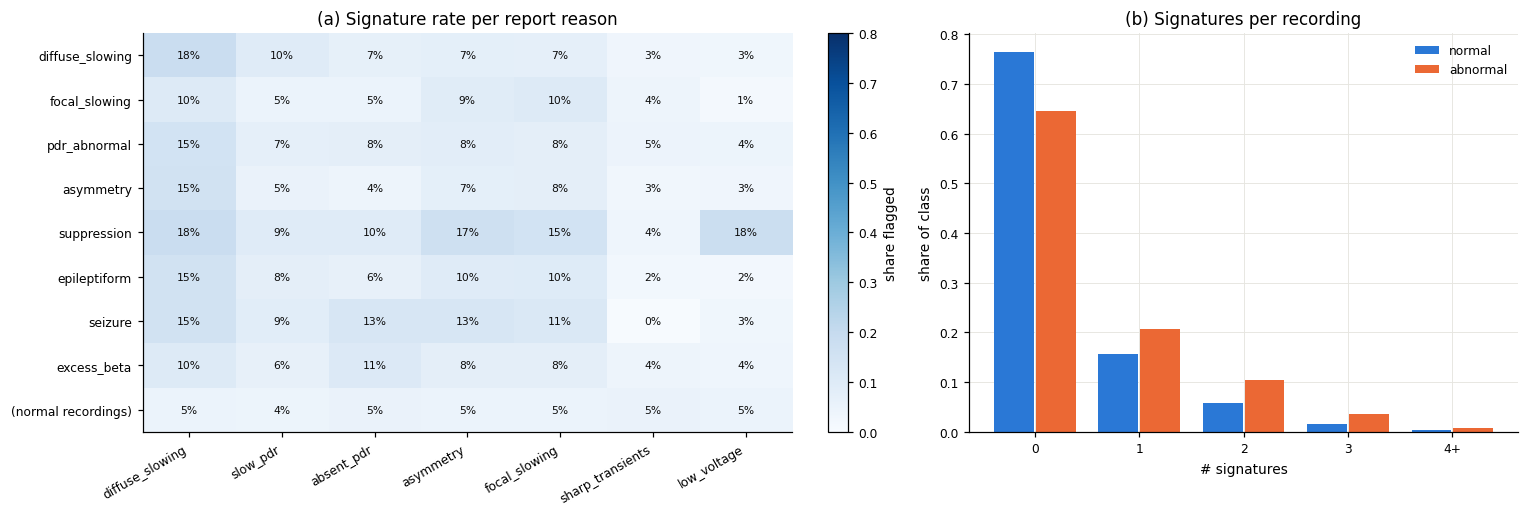

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
mat = pd.DataFrame({c: flags_tg[has_reason & reasons[c]].mean() for c in REASON_TO_SIGNATURE}).T
mat.loc["(normal recordings)"] = flags_tg[normal_rows].mean()
im = axes[0].imshow(mat.to_numpy(), cmap="Blues", vmin=0, vmax=0.8, aspect="auto")
axes[0].set_xticks(range(mat.shape[1]), mat.columns, rotation=30, ha="right")
axes[0].set_yticks(range(mat.shape[0]), mat.index)
for (i, j), v in np.ndenumerate(mat.to_numpy()):
    axes[0].text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.45 else "#0b0b0b")
axes[0].grid(False); axes[0].set_title("Signature rate per report reason")
fig.colorbar(im, ax=axes[0], fraction=0.04, label="share flagged")
t = pd.crosstab(n_sig_tg[labelled].clip(upper=4), tg.loc[labelled, "label"], normalize="columns")
x = np.arange(len(t))
for j, lab in enumerate(LABELS):
    axes[1].bar(x + (j - 0.5) * 0.4, t[lab], width=0.38, color=CLASS_COLORS[lab], label=lab)
axes[1].set_xticks(x, [str(i) if i < 4 else "4+" for i in t.index])
axes[1].set(title="Signatures per recording", xlabel="# signatures", ylabel="share of class"); axes[1].legend()
finish(fig, [axes[0], axes[1]])

### Table 13.4. Signatures by diagnosis

Lift of each signature in recordings with a diagnosis vs without it,
`labram/eval/meta_analysis.py::signature_by_condition`. Abnormal *and* normal labelled
recordings in the sheet, diagnoses with ≥ 30 positives. The top three signatures per
diagnosis by lift are shown.

In [37]:
dx = [c for c in CG["clinical"] if c.startswith("dx_")]
sbc = signature_by_condition(flags_tg[tg["in_sheet"] & labelled], in_sheet[dx])
t134 = (sbc.sort_values("lift", ascending=False).groupby("condition").head(3)
        .sort_values(["condition", "lift"], ascending=[True, False]).set_index(["condition", "signature"]))
display(numbered_table(t134.style.format({"n_positive": "{:,}", "prev_with": "{:.0%}", "prev_without": "{:.0%}",
                                          "lift": "x{:.1f}"}), "13.4", "Signatures by diagnosis"))

### Table 13.5. Drug effects on the qEEG of normal recordings

Report-normal recordings only, so pathology does not drive it. For each medication class:
recordings on it, and the median relative beta power, slowing ratio and PDR frequency (Hz)
with ($+$) and without ($-$) the class. `AUC beta` is the univariate ROC-AUC of relative beta
power for the class against the rest, oriented so that $> 0.5$ means more beta on the drug.

In [38]:
from sklearn.metrics import roc_auc_score
nrm = in_sheet[(in_sheet["label"] == "normal") & in_sheet["qeeg_rel_beta"].notna()]
rows = []
for m in [c for c in CG["clinical"] if c.startswith("med_")] + ["sedated"]:
    on = nrm[m].astype(float) == 1
    rows.append({"drug class": m, "recordings": int(on.sum()),
                 "beta +": nrm.loc[on, "qeeg_rel_beta"].median(), "beta -": nrm.loc[~on, "qeeg_rel_beta"].median(),
                 "slowing +": nrm.loc[on, "qeeg_slowing_ratio"].median(),
                 "slowing -": nrm.loc[~on, "qeeg_slowing_ratio"].median(),
                 "PDR + (Hz)": nrm.loc[on, "qeeg_pdr_freq"].median(), "PDR - (Hz)": nrm.loc[~on, "qeeg_pdr_freq"].median(),
                 "AUC beta": roc_auc_score(on, nrm["qeeg_rel_beta"])})
t135 = pd.DataFrame(rows).set_index("drug class")
display(numbered_table(t135.style.format({"recordings": "{:,}", "AUC beta": "{:.2f}"}, precision=3),
                       "13.5", "Drug effects on the qEEG of normal recordings"))

,recordings,beta +,beta -,slowing +,slowing -,PDR + (Hz),PDR - (Hz),AUC beta
drug class,,,,,,,,
med_anesthetic,718,0.065,0.151,0.566,0.206,9.500,10.000,0.27
med_benzodiazepine,"2,271",0.132,0.148,0.360,0.200,10.000,9.500,0.47
med_barbiturate,343,0.130,0.146,0.444,0.222,10.000,10.000,0.45
med_opioid,"1,561",0.100,0.152,0.432,0.199,9.500,10.000,0.37
med_antiseizure,"5,073",0.145,0.147,0.267,0.202,9.500,10.000,0.49
med_antipsychotic,433,0.149,0.146,0.230,0.228,9.500,10.000,0.51
sedated,"3,347",0.125,0.152,0.377,0.175,10.000,10.000,0.44


Section 13 checks Part I's computed "why abnormal" signatures against what the reports
actually say, and they come out **much weaker than TUAB suggested**.

* **What the reports say (Table 13.1).** Slowing dominates: diffuse slowing in 61% of the
  15,227 abnormal reports with a reason and focal slowing in 44%. Epileptiform findings
  (spikes, sharp waves, periodic discharges) are third at 33%, then suppression or
  attenuation at 20%. 56% of reports give more than one reason.
* **The signatures barely separate the classes here (Table 13.2).** 35% of abnormal and 24%
  of normal recordings carry at least one signature, against 72% vs 27% in TUAB. Diffuse
  slowing, the best signature, has a lift of ×3.0 instead of ×9.8.
* **Against the report's own reason (Table 13.3, Figure 13.1(a)).** The matching signature
  fires on 18% of the recordings whose report names diffuse slowing (×3.8 the rate in
  normals). For a report of suppression, the low-voltage signature fires on 18% (×3.6). For
  focal slowing, slow PDR and asymmetry it fires on only 7–10% (×1.5–2.1). Epileptiform
  findings are invisible to the kurtosis proxy (2%, ×0.5), as Part I suspected. Whatever
  the reason, 58–70% of these abnormal recordings carry *no* signature at all (48% for
  suppression).

Several things plausibly weaken the signatures compared with TUAB. The reference normals
are clinical "normal reads" rather than TUAB's curated normals. Whole recordings of up to
60 min mix wakefulness, drowsiness and sleep, and sleep alone looks like slowing. And a
report's reason often describes something brief or mild that a recording-wide median
spectrum averages away. TUAB's ×9.8 is therefore an optimistic estimate of how much
13 spectral summaries explain.

**Diagnoses (Table 13.4)** move the signatures only modestly. Traumatic brain injury is the
clearest case (diffuse slowing ×2.5, asymmetry ×2.3, focal slowing ×2.1); stroke raises
diffuse slowing (×1.7) and dementia a slow PDR (×1.9). Small groups (ADHD, n = 35) produce
noisy lifts. **Medication (Table 13.5)** leaves a large fingerprint on report-normal EEGs.
Anaesthetics nearly triple the slowing ratio (0.57 vs 0.21) and halve relative beta, and
benzodiazepines, barbiturates and opioids also raise slowing. Relative beta is *lower* on
these drugs (AUC 0.27–0.47). These are relative powers, so extra slow activity can hide an
absolute increase in fast activity. For a brain-age model, sedation therefore looks like an
"older", slower brain.

## 14. Can the meta features be used? Normal/abnormal and age

Metadata-only gradient-boosted trees (`metadata_baseline`, `metadata_age_baseline` in
`labram/eval/meta_analysis.py`) are trained on the cohort's train split and scored on the
subject-disjoint **val** split and on the **test** split (TUAB eval), one feature group at a
time. The metrics on the $n$ scored recordings, with $y_i$ the label, $p_i$ the predicted
probability, $a_i$ the age and $\hat a_i$ the predicted age (years):

$$ \operatorname{AUROC} = \Pr\left(p_i > p_j \mid y_i = 1,\ y_j = 0\right), \tag{14.1} $$

$$ \operatorname{BalAcc} = \tfrac12\left(\frac{\sum_i \mathbb{1}[p_i \ge 0.5,\ y_i = 1]}{\sum_i y_i} + \frac{\sum_i \mathbb{1}[p_i < 0.5,\ y_i = 0]}{\sum_i (1 - y_i)}\right), \tag{14.2} $$

$$ \operatorname{MAE} = \frac1n\sum_i \lvert \hat a_i - a_i\rvert, \qquad \operatorname{RMSE} = \sqrt{\frac1n\sum_i (\hat a_i - a_i)^2}, \tag{14.3} $$

$$ R^2 = 1 - \frac{\sum_i (\hat a_i - a_i)^2}{\sum_i (a_i - \bar a)^2}, \qquad \operatorname{MAE}_0 = \frac1n\sum_i \lvert \bar a_{\text{train}} - a_i\rvert . \tag{14.4} $$

$\operatorname{MAE}_0$ is the error of always predicting the mean training age: the floor
any age model has to beat. The `report findings` group (FIRDA, GPD, ...) is the report's
own EEG reading. It is listed only to show how much it leaks; a usable model must not use it.

### Table 14.1. Label information per meta feature

The 15 features with the highest univariate ROC-AUC (Eq. (14.1) of the feature itself,
oriented so 0.5 = none, `labram/eval/meta_analysis.py::univariate_auc`) on the labelled
train recordings. `coverage` is Eq. (8.1) within those recordings.

In [39]:
tr_lab = tg[(tg["split"] == "train") & labelled]
feats_all = available_features(tg, feature_groups=CG)
t141 = univariate_auc(tr_lab, feats_all, feature_groups=CG).head(15).set_index("feature")
display(numbered_table(t141.style.format({"auc": "{:.3f}", "coverage": "{:.0%}"}, precision=3),
                       "14.1", "Label information per meta feature"))

,group,auc,direction,coverage,median_normal,median_abnormal
feature,,,,,,
qeeg_theta_alpha_ratio,qeeg,0.690,higher=abnormal,100%,-0.023,0.234
qeeg_slowing_ratio,qeeg,0.679,higher=abnormal,100%,0.234,0.606
qeeg_rel_alpha,qeeg,0.668,lower=abnormal,100%,0.174,0.098
qeeg_aperiodic_slope,qeeg,0.661,lower=abnormal,100%,-1.487,-1.909
qeeg_rel_beta,qeeg,0.656,lower=abnormal,100%,0.145,0.084
qeeg_rel_delta,qeeg,0.644,higher=abnormal,100%,0.451,0.597
age,demographics,0.617,higher=abnormal,100%,49.000,57.000
qeeg_max_delta_asymmetry,qeeg,0.614,higher=abnormal,100%,0.183,0.239
qeeg_pdr_prominence,qeeg,0.607,lower=abnormal,100%,0.500,0.365


### Table 14.2. Metadata-only normal/abnormal classifier

AUROC (Eq. (14.1)) and balanced accuracy (Eq. (14.2)) per feature set, trained on the labelled
train recordings ($n$ = 23,781) and scored on the labelled val ($n$ = 3,064) and test (TUAB
eval, $n$ = 274) recordings. The TUAB column repeats Part I's result for the same feature
set where one exists.

In [40]:
va_lab = tg[(tg["split"] == "val") & labelled]
te_lab = tg[(tg["split"] == "test") & labelled]
experiments_tg = {
    "demographics (age, sex)": ["demographics"],
    "+ history (session no., year)": ["demographics", "history"],
    "acquisition only": ["acquisition"],
    "quality only": ["quality"],
    "clinical context only (dx, drugs)": ["clinical"],
    "qEEG only": ["qeeg"],
    "demographics + qEEG": ["demographics", "qeeg"],
    "demographics + qEEG + clinical": ["demographics", "qeeg", "clinical"],
    "all except acquisition/history/findings": ["demographics", "quality", "clinical", "qeeg"],
    "report findings only (leak)": ["report_findings"],
}
tuab_ref = {"demographics (age, sex)": "demographics (age, sex)", "+ history (session no., year)": "+ history (session no., year)",
            "acquisition only": "acquisition only", "quality only": "quality only", "qEEG only": "qEEG only",
            "demographics + qEEG": "demographics + qEEG"}
rows, models_tg = [], {}
for name, groups in experiments_tg.items():
    feats = available_features(tg, groups, CG)
    m_val, model = metadata_baseline(tr_lab, va_lab, feats)
    m_test, _ = metadata_baseline(tr_lab, te_lab, feats)
    rows.append({"features": name, "n_features": len(feats),
                 "val AUROC": m_val["auroc"], "val BalAcc": m_val["balanced_acc"],
                 "test AUROC": m_test["auroc"], "test BalAcc": m_test["balanced_acc"],
                 "TUAB AUROC (Part I)": res.loc[tuab_ref[name], "auroc"] if name in tuab_ref else np.nan})
    models_tg[name] = (model, feats)
t142 = pd.DataFrame(rows).set_index("features")
display(numbered_table(t142.style.format(precision=3, na_rep="–").bar(subset=["val AUROC"], vmin=0.5, vmax=1.0,
                                                                     color="#a8c8ef"),
                       "14.2", "Metadata-only normal/abnormal classifier"))

,n_features,val AUROC,val BalAcc,test AUROC,test BalAcc,TUAB AUROC (Part I)
features,,,,,,
"demographics (age, sex)",2,0.628,0.569,0.693,0.611,0.689
"+ history (session no., year)",4,0.660,0.597,0.711,0.620,0.727
acquisition only,20,0.620,0.569,0.505,0.486,0.686
quality only,6,0.654,0.586,0.718,0.647,0.574
"clinical context only (dx, drugs)",21,0.610,0.572,0.650,0.632,–
qEEG only,13,0.767,0.704,0.907,0.828,0.890
demographics + qEEG,15,0.769,0.706,0.915,0.854,0.901
demographics + qEEG + clinical,36,0.786,0.711,0.927,0.850,–
all except acquisition/history/findings,42,0.790,0.717,0.931,0.858,–


### Table 14.3. Metadata-only age regression

MAE, RMSE (Eq. (14.3)), $R^2$ and $\operatorname{MAE}_0$ (Eq. (14.4)), all in years, of
gradient-boosted age regression per feature set (age itself excluded). Trained on all train
recordings ($n$ = 25,613) and scored on all val recordings and on the report-normal val
recordings.

In [41]:
age_groups = {
    "sex only": ["sex_male"],
    "history (session no., year)": ["sex_male", "session_number", "year"],
    "acquisition only": CG["acquisition"],
    "acquisition + history": CG["acquisition"] + ["sex_male", "session_number", "year"],
    "quality only": CG["quality"],
    "clinical context only (dx, drugs)": CG["clinical"],
    "qEEG only": CG["qeeg"],
    "qEEG + sex": CG["qeeg"] + ["sex_male"],
    "qEEG + sex + quality + clinical": CG["qeeg"] + ["sex_male"] + CG["quality"] + CG["clinical"],
    "everything (incl. setup, history, label)": [c for c in feats_all if c != "age"] + ["is_abnormal"],
}
train_all = tg[tg["split"] == "train"]
val_all = tg[tg["split"] == "val"]
val_norm = val_all[val_all["label"] == "normal"]
rows, age_models = [], {}
for name, feats in age_groups.items():
    feats = [f for f in feats if f in tg and f != "age"]
    m_all, model = metadata_age_baseline(train_all, val_all, feats)                 # Eqs. (14.3), (14.4)
    m_norm, _ = metadata_age_baseline(train_all, val_norm, feats)
    rows.append({"features": name, "n_features": len(feats), "val MAE": m_all["mae"], "val RMSE": m_all["rmse"],
                 "val R2": m_all["r2"], "val-normal MAE": m_norm["mae"], "MAE0 (val)": m_all["mae_mean"]})
    age_models[name] = (model, feats)
t143 = pd.DataFrame(rows).set_index("features")
display(numbered_table(t143.style.format(precision=2).bar(subset=["val MAE"], color="#a8c8ef"),
                       "14.3", "Metadata-only age regression"))

,n_features,val MAE,val RMSE,val R2,val-normal MAE,MAE0 (val)
features,,,,,,
sex only,1,13.68,16.82,-0.00,13.91,13.68
"history (session no., year)",3,13.59,16.73,0.01,13.67,13.68
acquisition only,20,13.23,16.41,0.05,13.25,13.68
acquisition + history,23,13.16,16.36,0.05,13.05,13.68
quality only,6,13.54,16.67,0.02,13.76,13.68
"clinical context only (dx, drugs)",21,13.34,16.53,0.03,13.44,13.68
qEEG only,13,12.24,15.17,0.19,12.12,13.68
qEEG + sex,14,12.25,15.20,0.18,12.12,13.68
qEEG + sex + quality + clinical,41,11.96,14.82,0.22,11.74,13.68


### Figure 14.1. What tracks age, and what the age model uses

(a) Spearman $\rho$ between each meta feature and age within **report-normal** recordings,
so pathology does not drive it; the 14 strongest. (b) Increase in val MAE (years) when a
feature of the "qEEG + sex + quality + clinical" age model is shuffled (permutation
importance, 5 repeats); the 12 strongest. TUEG cohort.

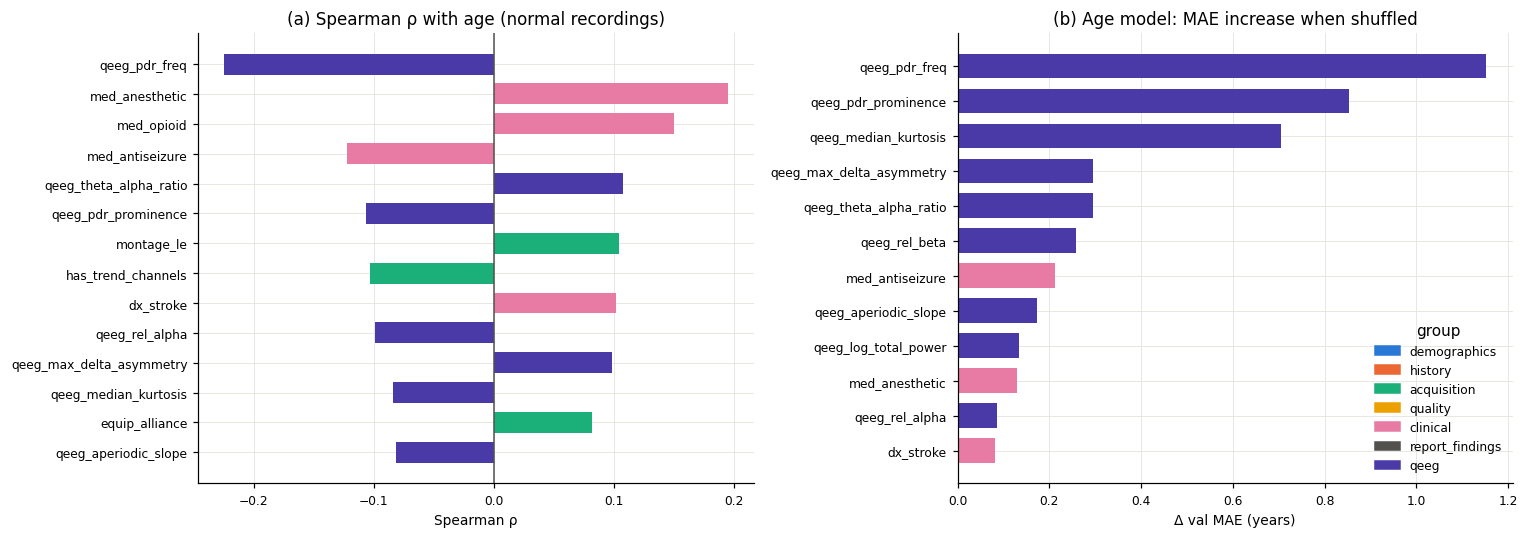

In [42]:
from sklearn.inspection import permutation_importance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
norm_all = tg[tg["label"] == "normal"]
cand = [f for f in feats_all if f != "age" and norm_all[f].nunique() > 1]
rho = pd.Series({f: spearmanr(norm_all[f], norm_all["age"], nan_policy="omit")[0] for f in cand}).dropna()
rho = rho.reindex(rho.abs().sort_values(ascending=False).index).head(14)
axes[0].barh(rho.index[::-1], rho.values[::-1], color=[COHORT_GROUP_COLORS[feature_group_of(f, CG)] for f in rho.index[::-1]],
             height=0.7)
axes[0].axvline(0, color="#52514e", lw=1)
axes[0].set(title="Spearman ρ with age (normal recordings)", xlabel="Spearman ρ")
model, feats = age_models["qEEG + sex + quality + clinical"]
pi = permutation_importance(model, val_all[feats].astype(float), val_all["age"], scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=feats).sort_values(ascending=False).head(12)
axes[1].barh(imp.index[::-1], imp.values[::-1], color=[COHORT_GROUP_COLORS[feature_group_of(f, CG)] for f in imp.index[::-1]],
             height=0.7)
axes[1].set(title="Age model: MAE increase when shuffled", xlabel="Δ val MAE (years)")
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COHORT_GROUP_COLORS.values()], COHORT_GROUP_COLORS.keys(),
               loc="lower right", title="group")
finish(fig, axes)

**Normal/abnormal (Table 14.1, Table 14.2).** On the TUEG val split the metadata-only
model is much weaker than on TUAB:
* qEEG alone reaches AUROC 0.767 (val), and all patient-level groups together 0.790;
* the best single features are the theta/alpha and slowing ratios (univariate AUC ≈ 0.68–0.69).

On the **TUAB eval** test set the same TUEG-trained qEEG model scores 0.907, *above* the
TUAB-trained 0.890 of Part I. So the cohort is harder, not the model worse: the TUEG
abnormal class is broader and subtler (Section 13). The other groups:
* **Clinical context** adds a little (0.769 → 0.786 val when added to demographics + qEEG).
  It is session-level knowledge from the same referral as the label, so it is only usable
  where it is known at prediction time.
* **Report findings** (FIRDA, LPD, ...) mark abnormal recordings by definition but are too
  rare (≈ 2%) to matter: AUROC 0.53.
* **Acquisition features** reach 0.620 on val, through the year / amplifier shortcut of
  Section 10. They collapse to 0.505 on TUAB eval, which has no 2002–2003 recordings.

**Age (Table 14.3, Figure 14.1).** The meta features say little about age.
* The trivial predictor (mean training age) has $\operatorname{MAE}_0$ = 13.7 years.
* Setup and history reach 13.2 ($R^2$ = 0.05), confirming Section 10: no setup shortcut.
* qEEG + sex reaches 12.2 ($R^2$ = 0.18), and everything together, including the label,
  11.8 ($R^2$ = 0.25).

Among normal recordings, no feature correlates with age beyond $\lvert\rho\rvert$ = 0.23.
The strongest is the PDR frequency, slower with age ($\rho$ = −0.23). Medication comes
next: anaesthetic and opioid use rise with age ($\rho$ = +0.20, +0.15). LaBraM's brain-age
fine-tunes reach about 6.3–6.5 years on the TUAB part of val
(`docs/data/tuh_cohort_eval_v1.csv`), half the error of these 13 summaries. Nearly all the
age information is therefore in the raw EEG, not in coarse spectral summaries.

## 15. TUEG cohort: findings and recommendations

### Table 15.1. TUAB vs TUEG cohort at a glance

The headline numbers of Part I and Part II side by side (computed from the tables above).

In [43]:
t151 = pd.DataFrame({
    "TUAB (Part I)": {
        "recordings / subjects": f"{len(df):,} / {df['subject'].nunique():,}",
        "abnormal share (labelled)": f"{df['is_abnormal'].mean():.0%}",
        "mean age normal / abnormal": f"{df.loc[df.label == 'normal', 'age'].mean():.1f} / {df.loc[df.label == 'abnormal', 'age'].mean():.1f}",
        "diagnoses / drugs / report reason": "none",
        "abnormal with >= 1 signature": f"{(flags.sum(axis=1)[df.label == 'abnormal'] > 0).mean():.0%}",
        "poor-quality tier": f"{(df['quality_tier'] == 'poor').mean():.1%}",
        "qEEG-only AUROC (eval)": f"{res.loc['qEEG only', 'auroc']:.3f}",
        "qEEG + sex age MAE (years)": "–",
    },
    "TUEG cohort (Part II)": {
        "recordings / subjects": f"{len(tg):,} / {tg['subject'].nunique():,}",
        "abnormal share (labelled)": f"{tg['is_abnormal'].mean():.0%}",
        "mean age normal / abnormal": f"{tg.loc[tg.label == 'normal', 'age'].mean():.1f} / {tg.loc[tg.label == 'abnormal', 'age'].mean():.1f}",
        "diagnoses / drugs / report reason": f"{tg['in_sheet'].mean():.0%} of recordings",
        "abnormal with >= 1 signature": f"{(n_sig_tg[tg.label == 'abnormal'] > 0).mean():.0%}",
        "poor-quality tier": f"{(tg['quality_tier'] == 'poor').mean():.1%}",
        "qEEG-only AUROC (eval)": f"{t142.loc['qEEG only', 'test AUROC']:.3f} (val {t142.loc['qEEG only', 'val AUROC']:.3f})",
        "qEEG + sex age MAE (years)": f"{t143.loc['qEEG + sex', 'val MAE']:.2f} (MAE0 {t143.loc['qEEG + sex', 'MAE0 (val)']:.2f})",
    },
})
display(numbered_table(t151, "15.1", "TUAB vs TUEG cohort at a glance"))

,TUAB (Part I),TUEG cohort (Part II)
recordings / subjects,"2,993 / 2,329","29,309 / 13,801"
abnormal share (labelled),49%,57%
mean age normal / abnormal,44.0 / 54.4,48.3 / 55.5
diagnoses / drugs / report reason,none,92% of recordings
abnormal with >= 1 signature,72%,35%
poor-quality tier,2.9%,7.8%
qEEG-only AUROC (eval),0.890,0.907 (val 0.767)
qEEG + sex age MAE (years),–,12.25 (MAE0 13.68)


### Recommendations

1. **Drop the 2 corrupt train recordings** (identical trace on every electrode, Section 11).
   Add an "all channels identical" check to the cohort builder; the existing flat/noisy
   checks cannot see it.
2. **Stratify brain-age evaluation by medication and diagnosis**, not only by normal/abnormal.
   Report MAE and age bias for sedated vs non-sedated, and for stroke / dementia / TBI vs
   none, on the val split. Sedation slows report-normal EEGs strongly (Table 13.5) and is more
   common in older patients, so it can masquerade as brain ageing.
3. **Treat the 2002–2003 / Bravo recordings as a label shortcut.** They are 4–9% abnormal and
   carry a distinct amplifier fingerprint (Tables 9.2, 10.2). Check abnormal detection within
   amplifier families, or exclude them from label-supervised training. For age they are
   harmless (Table 10.1).
4. **Use the report reasons for error analysis, not the qEEG signatures.** The signatures miss
   most report-stated reasons in TUEG (Table 13.3). The keyword categories of
   `report_reason_flags` give a per-recording "why" for 15k abnormal recordings: score
   abnormal-detection recall per reason, especially for epileptiform-only reports.
5. **Do not feed setup, history or report findings to a model** (Table 14.2), for the same
   reason as in Part I. Clinical flags are legitimate *conditioning* inputs only where they
   are known at prediction time; otherwise use them for stratification.
6. **Do not use these 13 qEEG summaries as the brain-age bar.** They reach $R^2$ = 0.18
   (Table 14.3), so beating them proves little. Compare LaBraM against the richer handcrafted
   feature set of `notebooks/eeg_feature_extraction_tuab.ipynb` instead.
7. **The *unlabelled* 7.5% (2,190 recordings)** have neither a TUAB label nor a sheet entry.
   They are fine for age, but any normal-only cohort must keep excluding them, as
   `normative_mask` does.